# Cảnh báo sớm hạ SpO₂ với ngưỡng do bác sĩ đặt: model hybrid nhận ngưỡng T

## Tóm tắt
Một model dùng cho mọi ngưỡng:

$$f(\text{60 phút lịch sử},\ T,\ \text{baseline}) \rightarrow \text{logit của } P(\text{SpO₂} < T \text{ liên tục} \ge 3 \text{ phút trong 30 phút tới})$$

Bác sĩ đổi T (COPD 88–92%, đa số bệnh khác 94–98%, theo BTS 2017) thì chỉ gửi config mới xuống vòng đeo tay, **không train lại**. Mọi đầu vào được biểu diễn **tương đối so với T** để model học quy luật "cách ngưỡng bao xa, đang đi xuống nhanh thế nào" thay vì một con số tuyệt đối. Model chạy trên ESP32-C3 dạng TFLite Micro INT8.

## Dữ liệu
- MIMIC-III Waveform Matched Subset, numerics, **chỉ record 1 Hz** (D1), lưới 1 phút. Nhãn được làm sạch bằng HR từ ECG (D2).
- `dataset_tc/{train,val,test}.npz`: cửa sổ 60 phút × 4 kênh, nhãn `Y[i, T]` và cờ `OK[i, T]` (đầu vào chưa có sự kiện < T) cho T ∈ {86,…,94}, `baseline` (trung vị SpO₂ 6–24 giờ trước cửa sổ) và `baseline_hours`. Hợp đồng dữ liệu ghi ở đầu `tc_core.py`.
- **T = 89 và 91 không dùng để train**, chỉ để kiểm tra khả năng nội suy sang ngưỡng chưa thấy.
- Chia theo bệnh nhân 70/15/15.

## Phương pháp
| Bước | Kỹ thuật | Lý do |
|---|---|---|
| Đầu vào chuỗi | `spo2_mean − T`, `spo2_min − T`, `spo2_valid`, `pulse_mean` + 2 kênh mask; z-score theo train (sau khi đã trừ T) | học quy luật tương đối, không học con số 88 |
| Đầu vào bảng | 23 đặc trưng: tương đối với T, xu hướng, mạch, baseline, chất lượng, T | tín hiệu chính là "khoảng cách tới ngưỡng" |
| Lấy mẫu T | mỗi cửa sổ một T ngẫu nhiên mỗi epoch (không nhân bản ×7), chỉ tính loss khi `OK[i, T]` | dữ liệu không phình, mọi T được học đều |
| Mất cân bằng | giữ toàn bộ mẫu dương, lấy 30% mẫu âm với trọng số bù 1/0,3 | nhanh hơn mà loss vẫn không lệch |
| Loss | BCE (logit) + λ·relu(logit_T − logit_{T+1}) | ép tính đơn điệu: T cao hơn thì rủi ro không thể thấp hơn |
| Dừng sớm | trung bình AUPRC trên các T train của val; 3 seed; checkpoint mỗi epoch | |
| Ngưỡng cảnh báo | chọn trên val theo **báo giả/ngày thật** (sim_alert, sau persistence + cooldown), bảng T → ngưỡng, làm mượt theo T | test giữ nguyên ngưỡng |
| Triển khai | TFLite INT8, 2 đầu vào, đầu ra logit; `meta.json` mang bảng ngưỡng | firmware chỉ cần bảng, không cần train |

## Quy ước đánh giá
- Val để dừng sớm, chọn seed, chọn ngưỡng, chọn persistence. **Test chỉ mở một lần** (mục 9).
- Khoảng tin cậy 95% bootstrap **theo bệnh nhân**; so sánh model bằng chênh AUPRC theo cặp.
- Báo giả báo cáo là **cảnh báo thật** sau persistence và cooldown; con số đếm theo cửa sổ chỉ là cận trên.

## Danh mục đồ thị
G1 AUPRC theo T · G2 PR/ROC theo T · G3 bắt sự kiện vs báo giả/ngày so với luật · G4 đơn điệu · G5 hiệu chuẩn · G6 sim_alert theo T · G7 báo trước và báo giả theo bệnh nhân · G8 ablation · G9 INT8 vs float · G10 tầng Critical · (G11 ở `10_lightgbm_tc.ipynb`)

## Mục lục
1 Cấu hình · 2 Dữ liệu · 3 Mô hình · 4 Huấn luyện · 5 Đánh giá trên val · 6 Ablation · 7 Mô phỏng cảnh báo trên val · 8 Chốt cấu hình · 9 Test (một lần) · 10 Xuất model · 11 Suy luận thử · 12 Tổng kết

## 1. Cấu hình
| Nhóm | Tham số | Ý nghĩa |
|---|---|---|
| Đường dẫn | `DATA_DIR`, `CLEAN_DIR`, `RUN_ROOT`, `EXPORT_DIR` | dữ liệu cửa sổ; lưới 1 phút (cho mô phỏng); checkpoint; model xuất |
| Ngưỡng | `T_TRAIN`, `T_HOLDOUT`, `T_RANGE` | T dùng để train; T để riêng kiểm tra nội suy; khoảng T hợp lệ trên web/firmware |
| Huấn luyện | `SEEDS`, `BATCH`, `MAX_EPOCHS`, `PATIENCE`, `LR`, `NEG_RATE`, `LAMBDA_MONO` | `NEG_RATE`: tỷ lệ giữ mẫu âm mỗi epoch; `LAMBDA_MONO`: hệ số phạt đơn điệu |
| Kiến trúc | `FILTERS`, `KERNEL`, `DROPOUT`, `TAB_UNITS` | nhánh chuỗi và nhánh đặc trưng |
| So sánh | `BASELINES` | điểm LightGBM đã lưu bởi `10_lightgbm_tc.ipynb`; luật được tính ngay trong notebook |
| Cảnh báo | `TIERS` | ngân sách **báo giả/ngày thật**, persistence `k/n`, cooldown (phút) của tầng Watch và Alert |
| Critical | `CRIT`, `CRIT_DEPLOY` | các ngưỡng Critical để thống kê (G10) và cấu hình mặc định gửi xuống thiết bị |

**Phục hồi:** chạy lại notebook từ đầu, mỗi run tự tiếp tục từ epoch cuối đã lưu. Không đổi `CFG` giữa chừng; thử cấu hình mới thì đổi `RUN_ROOT`.

In [1]:
import os, json, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tqdm.auto import tqdm
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score
import tc_core as C, eval_utils as E, sim_alert as SA

CFG = dict(
    DATA_DIR="../data/data/dataset_tc", CLEAN_DIR="../data/data/clean_1min",
    RUN_ROOT="runs/hybrid_tc_v1", EXPORT_DIR="models_v3", NAME="hybrid_tc",
    T_TRAIN=C.T_TRAIN, T_HOLDOUT=C.T_HOLDOUT, T_RANGE=C.T_RANGE,
    SEEDS=(1, 2, 3), BATCH=512, MAX_EPOCHS=40, PATIENCE=6, LR=1e-3,
    NEG_RATE=0.3, LAMBDA_MONO=1.0,
    FILTERS=(16, 32, 32), KERNEL=5, DROPOUT=0.2, TAB_UNITS=32,
    BASELINES=dict(lgbm="runs/lgbm_tc"),
    TIERS=dict(watch=dict(fa_day=3.0, k=1, n=1, cooldown=30), alert=dict(fa_day=1.0, k=1, n=1, cooldown=60)),
    FA_GRID=(0.25, 0.5, 1, 2, 4),                 # ngân sách báo giả/ngày để vẽ G3
    THR_SMOOTH="isotonic",                        # làm mượt bảng T -> ngưỡng: isotonic | linear | none
    CRIT=dict(crit_T=(80, 82, 85, 88), n_min=3, sqi_min=0.5, hr_low=40, hr_high=140, cooldown=30),
    CRIT_DEPLOY=dict(crit_T=85, n_min=3, sqi_min=0.5, hr_low=40, hr_high=140, cooldown=30),
    RUN_ABLATION=True, ABL_SEED=1,
)
ROOT = CFG["RUN_ROOT"]; os.makedirs(ROOT, exist_ok=True)
T_TR, T_HO = [int(t) for t in CFG["T_TRAIN"]], [int(t) for t in CFG["T_HOLDOUT"]]
sig = lambda z: 1 / (1 + np.exp(-z))
print("TensorFlow", tf.__version__, "| CPU:", os.cpu_count(), "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | CPU: 12 | GPU: []


## 2. Dữ liệu

### 2.1 Nạp cửa sổ và thống kê nhãn theo T
Mỗi tập có `X` (n, 60, 4), `Y` và `OK` (n, K) theo `T_list`, `baseline`, `baseline_hours`, `pid`, `rec`, `start`. Bảng dưới là **"bảng số cửa sổ và tỷ lệ dương theo T"**: tỷ lệ dương tăng mạnh theo T, nên AUPRC tuyệt đối ở các T khác nhau không so sánh trực tiếp được; hãy đọc kèm hệ số so với ngẫu nhiên.

Phần không phụ thuộc T của đặc trưng (mức SpO₂, xu hướng, mạch, chất lượng, bảng `frac_below` cho mọi ngưỡng nguyên) được tính một lần và lưu ở `features_tc/`; đặc trưng tại một T cụ thể được ghép lại rất nhanh trong lúc train.

n_ok                      n_pos                 prevalence          \
split     test     train      val    test   train     val       test   train   
T                                                                              
86     53435.0  235908.0  50492.0   192.0  1119.0   253.0     0.0036  0.0047   
87     53170.0  234794.0  50186.0   292.0  1447.0   313.0     0.0055  0.0062   
88     52744.0  233075.0  49743.0   437.0  1893.0   402.0     0.0083  0.0081   
89     52023.0  230632.0  49275.0   637.0  2562.0   480.0     0.0122  0.0111   
90     50833.0  226968.0  48521.0   862.0  3482.0   662.0     0.0170  0.0153   
91     49136.0  220661.0  47059.0  1151.0  4904.0   952.0     0.0234  0.0222   
92     46971.0  212078.0  45152.0  1546.0  6321.0  1342.0     0.0329  0.0298   
93     43721.0  199406.0  41889.0  1966.0  8107.0  1769.0     0.0450  0.0407   
94     39192.0  181815.0  37448.0  2247.0  9695.0  2161.0     0.0573  0.0533   

              pat_pos               
split     val    test  train   val  
T                                   
86     0.0050    17.0   80.0  17.0  
87     0.0062    21.0   94.0  20.0  
88     0.0081    25.0  118.0  25.0  
89     0.0097    30.0  146.0  28.0  
90     0.0136    37.0  176.0  32.0  
91     0.0202    46.0  212.0  44.0  
92     0.0297    57.0  249.0  51.0  
93     0.0422    63.0  291.0  57.0  
94     0.0577    69.0  323.0  70.0

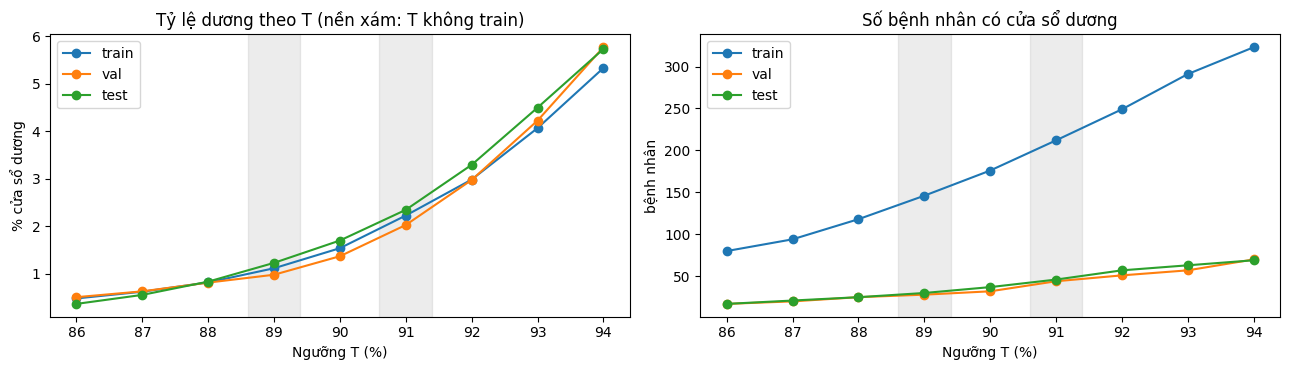

Cửa sổ train có baseline ≥ 1.0 giờ: 96.6% | baseline_hours trung vị 19.0 giờ (thiếu baseline thì dùng SpO₂ trung bình của chính cửa sổ)


In [2]:
DS = {k: C.load_split(CFG["DATA_DIR"], k) for k in ("train", "val", "test")}
T_LIST = DS["val"]["T_list"]
assert all((DS[k]["T_list"] == T_LIST).all() for k in DS) and set(T_TR + T_HO) <= set(T_LIST.tolist())
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    assert not set(DS[a]["pid"]) & set(DS[b]["pid"]), f"Có bệnh nhân nằm ở cả {a} và {b}"
FEAT_DIR = os.path.join(os.path.dirname(CFG["DATA_DIR"].rstrip("/")), "features_tc")
ST = {k: C.stats_cache(DS[k], f"{FEAT_DIR}/{k}_stats.npz") for k in DS}

LT = C.label_table(DS, T_LIST)
display(LT.pivot(index="T", columns="split", values=["n_ok", "n_pos", "prevalence", "pat_pos"]).round(4))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for k, g in LT.groupby("split", sort=False):
    ax[0].plot(g["T"], g["prevalence"] * 100, "o-", label=k); ax[1].plot(g["T"], g["pat_pos"], "o-", label=k)
for a in ax:
    for t in T_HO: a.axvspan(t - .4, t + .4, color="gray", alpha=.15)
    a.set_xlabel("Ngưỡng T (%)"); a.legend()
ax[0].set(ylabel="% cửa sổ dương", title="Tỷ lệ dương theo T (nền xám: T không train)"); ax[1].set(ylabel="bệnh nhân", title="Số bệnh nhân có cửa sổ dương")
plt.tight_layout(); plt.show()
bt, bh = DS["train"]["baseline"], DS["train"]["baseline_hours"]
print(f"Cửa sổ train có baseline ≥ {C.BASE_MIN_HOURS} giờ: {np.mean(np.isfinite(bt) & (bh >= C.BASE_MIN_HOURS)):.1%} "
      f"| baseline_hours trung vị {np.nanmedian(bh):.1f} giờ (thiếu baseline thì dùng SpO₂ trung bình của chính cửa sổ)")

### 2.2 Unit test đặc trưng tương đối
Kiểm tra trước khi train: (1) đổi T một lượng ΔT thì mọi đặc trưng `*_rT` và `base_rT` dịch đúng −ΔT, các đặc trưng khác giữ nguyên; (2) đường tính nhanh `tab_from_stats` khớp bản tham chiếu `make_features` (bản firmware phải làm theo); (3) chuỗi dịch đúng; (4) loại sự kiện nhiễu bằng HR; (5) `fire_times` vector hóa khớp bản cũ; (6) lấy mẫu T chỉ chọn ô `OK`.

In [3]:
import test_tc_core as TT
for n_, f_ in vars(TT).items():
    if n_.startswith("test_"): f_()
i_ = np.arange(min(3000, len(DS["val"]["X"]))); dv_ = DS["val"]
F88, F92 = C.tab_from_stats(ST["val"], 88, i_), C.tab_from_stats(ST["val"], 92, i_)
for c in C.TAB_REL[:5] + ["base_rT"]: assert np.allclose((F92[c] - F88[c]).dropna(), -4, atol=1e-4), c
Fref = C.make_features(dv_["X"][i_], 90, dv_["baseline"][i_], dv_["baseline_hours"][i_])
assert np.allclose(C.tab_from_stats(ST["val"], 90, i_).to_numpy(), Fref.to_numpy(), atol=1e-4, equal_nan=True)
print(f"Unit test: OK | {len(C.tab_cols())} đặc trưng bảng:", C.tab_cols())

Unit test: OK | 23 đặc trưng bảng: ['sp_mean_rT', 'sp_p10_rT', 'mn_min60_rT', 'mn_min10_rT', 'sp_last5_rT', 'frac_lt_T', 'frac_lt_T2', 'frac_lt_T4', 'sp_slope60', 'sp_slope30', 'sp_d_last10_first30', 'sp_std60', 'sp_std15', 'pu_mean', 'pu_slope30', 'pu_d_last10_first30', 'pu_std60', 'base_rT', 'last5_rbase', 'base_hours', 'valid_mean', 'sp_nan_frac', 'T']


## 3. Mô hình hybrid nhận T

```text
seq (60×6) → Conv1D(16,k5) → MaxPool → Conv1D(32,k5) → MaxPool → Conv1D(32,k3) → GlobalAvgPool ─┐
tab (23)   → Dense(32, ReLU) ───────────────────────────────────────────────────────────────────┴→ Concat → Dropout → Dense(16) → Dense(1) = logit
```
- Kiến trúc giữ như bản v2; T đi vào qua **cả hai nhánh**: kênh SpO₂ đã trừ T (nhánh chuỗi) và các đặc trưng tương đối + T (nhánh bảng).
- Khoảng 8 nghìn tham số, mục tiêu < 30 KB khi INT8. Đầu ra là logit (sigmoid ở ngoài model).

In [4]:
def build_hybrid(n_tab, lr=CFG["LR"]):
    L = keras.layers
    s = keras.Input((C.IN_MIN, 6), name="seq"); t = keras.Input((n_tab,), name="tab"); x = s
    for i, f in enumerate(CFG["FILTERS"]):
        x = L.Conv1D(f, CFG["KERNEL"] if i < 2 else 3, padding="same", activation="relu")(x)
        if i < 2: x = L.MaxPooling1D(2)(x)
    z = L.Concatenate()([L.GlobalAveragePooling1D()(x), L.Dense(CFG["TAB_UNITS"], activation="relu")(t)])
    z = L.Dense(16, activation="relu")(L.Dropout(CFG["DROPOUT"])(z))
    m = keras.Model([s, t], L.Dense(1)(z), name="hybrid_tc")                     # đầu ra: logit
    m.compile(keras.optimizers.Adam(lr), keras.losses.BinaryCrossentropy(from_logits=True)); return m
build_hybrid(len(C.tab_cols())).summary()

Model: "hybrid_tc"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ seq (InputLayer)    │ (None, 60, 6)     │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 60, 16)    │        496 │ seq[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 30, 16)    │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 30, 32)    │      2,592 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 15, 32)    │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 15, 32)    │      3,104 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tab (InputLayer)    │ (None, 23)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ conv1d_2[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │        768 │ tab[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64)        │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16)        │      1,040 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         17 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,017 (31.32 KB)

 Trainable params: 8,017 (31.32 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Huấn luyện

### 4.1 Thuật toán
Mỗi epoch:
1. `tc_core.sample_epoch`: mỗi cửa sổ nhận **một** T ngẫu nhiên, đều trên các T train mà cửa sổ còn `OK`; giữ mọi mẫu dương, giữ `NEG_RATE` mẫu âm với trọng số `1/NEG_RATE`. Dữ liệu không bị nhân bản 7 lần, mọi T được chọn ngang nhau.
2. Mỗi batch chạy model hai lần, tại T và T+1 trên cùng cửa sổ. Loss = BCE có trọng số tại T + `LAMBDA_MONO` × trung bình `relu(logit_T − logit_{T+1})`.
3. Cuối epoch: chấm val ở **mọi** T. Tiêu chí dừng sớm là trung bình AUPRC trên các T train. Ghi thêm AUPRC trung bình ở T không train (chỉ để theo dõi, không dùng để chọn) và tỷ lệ cặp T kề nhau vi phạm đơn điệu.
4. Lưu `last.keras` (cả trạng thái optimizer), `best.keras`, `state.json`; ghi qua file tạm rồi đổi tên.

Chuẩn hóa (`norm_*.npz`) tính trên train **sau khi** đã đổi sang giá trị tương đối, với T rút ngẫu nhiên trong các T train.

### 4.2 Cách đọc bảng
`loss` là BCE train (có trọng số), `mono` là phạt đơn điệu, `val_loss`/`val_auprc` tính trên val ở các T train, `ho_auprc` ở T không train, `viol` là tỷ lệ cặp T kề nhau có P giảm. `gap = auprc(train, tập con) − val_auprc`. Val chỉ có vài chục bệnh nhân dương ở T thấp nên dao động giữa các epoch là bình thường; đọc theo xu hướng.

In [5]:
def get_norm(rel=True, use_base=True):
    p = f"{ROOT}/norm_rel{int(rel)}_base{int(use_base)}.npz"
    if os.path.exists(p): return C.load_norm(p)
    nm = C.fit_norm(DS["train"]["X"], ST["train"], T_TR, rel, use_base); C.save_norm(p, nm); return nm

def predict_T(model, k, nm, T, idx=None, bs=8192):
    d = DS[k]; idx = np.arange(len(d["X"])) if idx is None else np.asarray(idx)
    T = np.broadcast_to(np.asarray(T), (len(idx),)); out = np.empty(len(idx), np.float32)
    for a in range(0, len(idx), bs):
        out[a:a + bs] = np.asarray(model.predict_on_batch(C.inputs(d, ST[k], nm, T[a:a + bs], idx[a:a + bs]))).ravel()
    return out

def score_matrix(model, k, nm, T_list=None):
    """Logit (n, K) của mọi cửa sổ ở các T trong T_list (mặc định toàn bộ T_LIST); cột không tính để NaN."""
    S = np.full((len(DS[k]["X"]), len(T_LIST)), np.nan, np.float32)
    for T in (T_LIST if T_list is None else T_list): S[:, C.col(DS[k], T)] = predict_T(model, k, nm, int(T))
    return S

def val_metrics(Z, T_ch):
    d, ls, aps = DS["val"], [], []
    for T in T_ch:
        j = C.col(d, T); ok = d["OK"][:, j]; y = d["Y"][ok, j]; z = Z[ok, j].astype(np.float64)
        ls.append(np.mean(np.maximum(z, 0) - z * y + np.log1p(np.exp(-np.abs(z))))); aps.append(average_precision_score(y, z))
    return float(np.mean(ls)), float(np.mean(aps))

_bce = keras.losses.BinaryCrossentropy(from_logits=True, reduction="none")
def make_step(model, lam):
    opt, var = model.optimizer, model.trainable_variables
    if not opt.built: opt.build(var)
    @tf.function(reduce_retracing=True)
    def step(s0, t0, s1, t1, y, w):
        with tf.GradientTape() as tape:
            z0 = model([s0, t0], training=True)[:, 0]
            l_bce = tf.reduce_sum(w * _bce(y[:, None], z0[:, None])) / tf.reduce_sum(w)
            l_mono = tf.reduce_mean(tf.nn.relu(z0 - model([s1, t1], training=True)[:, 0])) if lam > 0 else tf.constant(0.0)
            loss = l_bce + lam * l_mono
        opt.apply_gradients(zip(tape.gradient(loss, var), var))
        return l_bce, l_mono
    return step

def _save(model, path): tmp = path + ".tmp.keras"; model.save(tmp); os.replace(tmp, path)

def train_run(name, seed, var):
    """var: dict(rel, use_base, fixed_T). fixed_T = số -> model riêng cho một T (ablation), không phạt đơn điệu."""
    run = f"{ROOT}/{name}/s{seed}"; os.makedirs(run, exist_ok=True)
    fixed = var.get("fixed_T"); T_ch = [fixed] if fixed else T_TR; lam = 0.0 if fixed else CFG["LAMBDA_MONO"]
    nm = get_norm(var.get("rel", True), var.get("use_base", True)); d = DS["train"]; B = CFG["BATCH"]
    if os.path.exists(f"{run}/state.json") and os.path.exists(f"{run}/last.keras"):
        st = json.load(open(f"{run}/state.json", encoding="utf-8")); model = keras.models.load_model(f"{run}/last.keras")
        print(f"♻ {name}/s{seed}: tiếp tục từ epoch {st['epoch']} (tốt nhất epoch {st['best_epoch']}, val_auprc {st['best']:.4f})")
    else:
        keras.utils.set_random_seed(seed); model = build_hybrid(len(nm["tab_cols"]))
        st = dict(epoch=0, best=-1.0, best_epoch=-1, wait=0, done=False, history=[])
        json.dump(dict(CFG=CFG, var=var), open(f"{run}/config.json", "w", encoding="utf-8"), indent=1, default=str)
    if st["done"]: print(f"✔ {name}/s{seed}: đã xong (val_auprc {st['best']:.4f} ở epoch {st['best_epoch']})"); return st
    step = make_step(model, lam)
    rs = np.random.default_rng(0); sub = rs.choice(len(d["X"]), min(40000, len(d["X"])), replace=False)
    Tsub = rs.choice(T_ch, len(sub)); jsub = np.array([C.col(d, t) for t in Tsub]); ksub = d["OK"][sub, jsub]
    sub, Tsub, ysub = sub[ksub], Tsub[ksub], d["Y"][sub[ksub], jsub[ksub]]
    outer = tqdm(total=CFG["MAX_EPOCHS"], initial=st["epoch"], desc=f"{name}/s{seed}", unit="epoch")
    outer.write(f"{'Ep':>3} | {'loss':>7} {'mono':>6} {'val_loss':>8} | {'auprc':>6} {'val_auprc':>9} {'ho_auprc':>8} | {'viol':>6} | {'giây':>5} | ghi chú")
    for ep in range(st["epoch"], CFG["MAX_EPOCHS"]):
        t0 = time.time(); rng = np.random.default_rng(seed * 1000 + ep)
        idx, T, y, w = C.sample_epoch(d, T_ch, CFG["NEG_RATE"], rng, fixed_T=fixed)
        lb = lm = 0.0; nb = 0
        for a in tqdm(range(0, len(idx), B), desc=f"Epoch {ep + 1}", leave=False):
            ii, tt = idx[a:a + B], T[a:a + B]
            x0 = C.inputs(d, ST["train"], nm, tt, ii); x1 = C.inputs(d, ST["train"], nm, tt + 1, ii) if lam else x0
            l1, l2 = step(x0["seq"], x0["tab"], x1["seq"], x1["tab"], y[a:a + B], w[a:a + B]); lb += float(l1); lm += float(l2); nb += 1
        Zv = score_matrix(model, "val", nm, T_ch if fixed else None); vl, va = val_metrics(Zv, T_ch)
        r = dict(epoch=ep + 1, loss=lb / nb, mono=lm / nb, val_loss=vl, val_auprc=va, n_samples=int(len(idx)),
                 auprc=float(average_precision_score(ysub, predict_T(model, "train", nm, Tsub, sub))))
        r["gap"] = r["auprc"] - va
        r["ho_auprc"] = E.mean_auprc(Zv, DS["val"], T_HO) if not fixed else np.nan
        r["viol"] = E.monotonic_report(Zv, T_LIST)["adjacent"] if not fixed else np.nan
        r["sec"] = time.time() - t0; H = st["history"]; H.append(r); note = []
        if va > st["best"]:
            st["best"], st["best_epoch"], st["wait"] = va, r["epoch"], 0; _save(model, f"{run}/best.keras"); note.append("★ tốt nhất")
        else: st["wait"] += 1
        if len(H) >= 3 and H[-1]["val_loss"] > H[-2]["val_loss"] > H[-3]["val_loss"] and H[-1]["loss"] < H[-3]["loss"]:
            note.append("⚠ val_loss tăng 2 epoch liền (nghi overfit)")
        st["epoch"] = r["epoch"]; st["done"] = st["wait"] >= CFG["PATIENCE"] or r["epoch"] >= CFG["MAX_EPOCHS"]
        _save(model, f"{run}/last.keras")
        json.dump(st, open(f"{run}/state.json.tmp", "w", encoding="utf-8")); os.replace(f"{run}/state.json.tmp", f"{run}/state.json")
        outer.update(1)
        outer.write(f"{r['epoch']:>3} | {r['loss']:7.4f} {r['mono']:6.4f} {vl:8.4f} | {r['auprc']:6.3f} {va:9.4f} {r['ho_auprc']:8.4f} | "
                    f"{r['viol']:6.4f} | {r['sec']:5.0f} | {' '.join(note)}")
        if st["done"]:
            outer.write("■ Dừng: " + ("hết kiên nhẫn (early stopping)" if st["wait"] >= CFG["PATIENCE"] else "đủ số epoch tối đa")); break
    outer.close(); return st

def load_best(name, s): return keras.models.load_model(f"{ROOT}/{name}/s{s}/best.keras")

def seed_scores(name, s, k, nm, T_list=None):
    """Logit của best.keras trên tập k, có lưu đĩa theo epoch tốt nhất (đổi checkpoint thì tự tính lại)."""
    st = json.load(open(f"{ROOT}/{name}/s{s}/state.json", encoding="utf-8")); p = f"{ROOT}/{name}/s{s}/logit_{k}_e{st['best_epoch']}.npy"
    if os.path.exists(p): return np.load(p)
    Z = score_matrix(load_best(name, s), k, nm, T_list); np.save(p, Z); return Z

### 4.3 Chạy (tự resume)
Model chính: đầu vào tương đối + baseline, một model chung cho mọi T, 3 seed.

In [6]:
MAIN = dict(rel=True, use_base=True, fixed_T=None)
NM = get_norm(True, True)
RUNS = {s: train_run("main", s, MAIN) for s in CFG["SEEDS"]}

♻ main/s1: tiếp tục từ epoch 26 (tốt nhất epoch 20, val_auprc 0.1649)
✔ main/s1: đã xong (val_auprc 0.1649 ở epoch 20)
♻ main/s2: tiếp tục từ epoch 36 (tốt nhất epoch 30, val_auprc 0.1704)
✔ main/s2: đã xong (val_auprc 0.1704 ở epoch 30)
♻ main/s3: tiếp tục từ epoch 40 (tốt nhất epoch 39, val_auprc 0.1738)
✔ main/s3: đã xong (val_auprc 0.1738 ở epoch 39)


### 4.4 Đường cong học
Bốn biểu đồ, mỗi seed một màu: loss (nét đứt = train, liền = val), AUPRC (đứt = train tập con, liền = val ở T train, chấm = val ở T không train), phạt và tỷ lệ vi phạm đơn điệu, gap AUPRC. Đường chấm dọc là epoch tốt nhất. Đường cong ổn định khi ba seed gần nhau và `viol` giảm về gần 0.

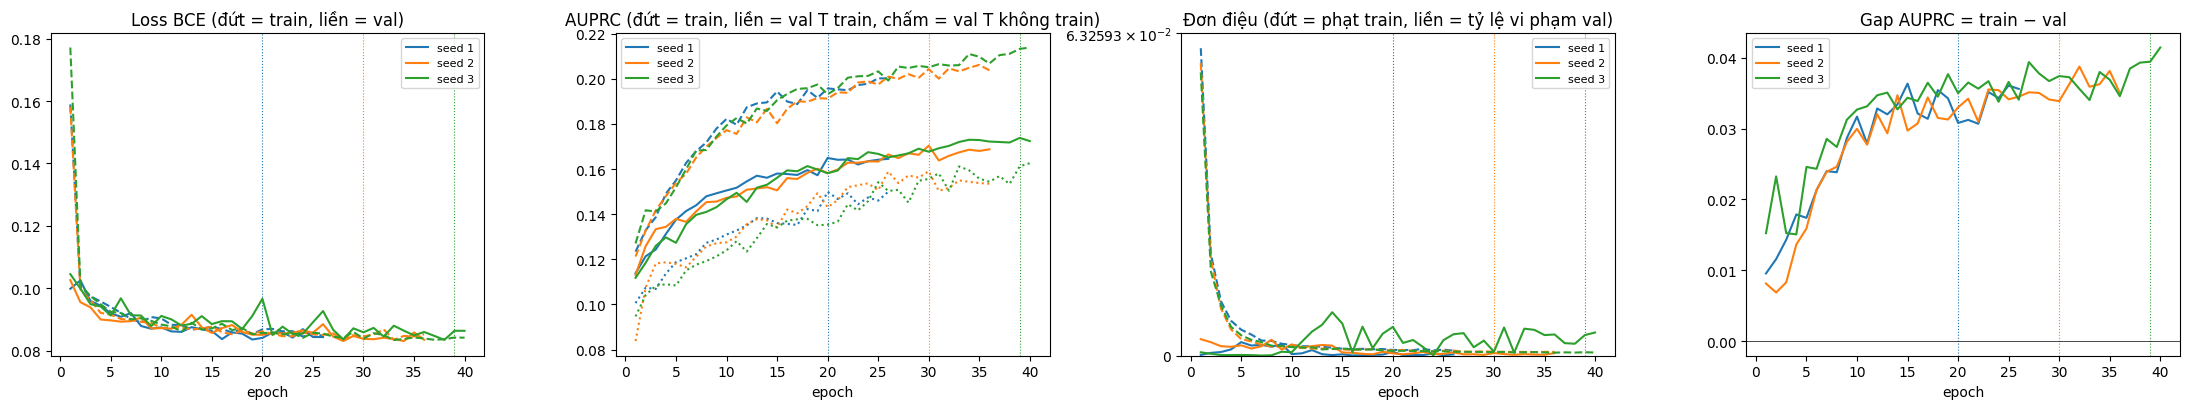

,epoch_tot_nhat,val_auprc_T_train,so_epoch
seed 1,20.0,0.1649,26.0
seed 2,30.0,0.1704,36.0
seed 3,39.0,0.1738,40.0


In [7]:
fig, ax = plt.subplots(1, 4, figsize=(22, 4.2))
for i, s in enumerate(CFG["SEEDS"]):
    H = pd.DataFrame(RUNS[s]["history"]); c = f"C{i}"; b = RUNS[s]["best_epoch"]
    ax[0].plot(H.epoch, H.loss, c=c, ls="--"); ax[0].plot(H.epoch, H.val_loss, c=c, label=f"seed {s}")
    ax[1].plot(H.epoch, H.auprc, c=c, ls="--"); ax[1].plot(H.epoch, H.val_auprc, c=c, label=f"seed {s}"); ax[1].plot(H.epoch, H.ho_auprc, c=c, ls=":")
    ax[2].plot(H.epoch, H.mono, c=c, ls="--"); ax[2].plot(H.epoch, H.viol, c=c, label=f"seed {s}")
    ax[3].plot(H.epoch, H.gap, c=c, label=f"seed {s}")
    for a in ax: a.axvline(b, ls=":", c=c, lw=.8)
ax[0].set(title="Loss BCE (đứt = train, liền = val)", xlabel="epoch")
ax[1].set(title="AUPRC (đứt = train, liền = val T train, chấm = val T không train)", xlabel="epoch")
ax[2].set(title="Đơn điệu (đứt = phạt train, liền = tỷ lệ vi phạm val)", xlabel="epoch", yscale="symlog", ylim=(0, None))
ax[3].set(title="Gap AUPRC = train − val", xlabel="epoch"); ax[3].axhline(0, c="k", lw=.5)
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()
display(pd.DataFrame({f"seed {s}": dict(epoch_tot_nhat=RUNS[s]["best_epoch"], val_auprc_T_train=round(RUNS[s]["best"], 4),
                                        so_epoch=RUNS[s]["epoch"]) for s in CFG["SEEDS"]}).T)

## 5. Đánh giá trên val

### 5.1 AUPRC theo T (G1) và PR/ROC (G2)
- Mỗi seed dùng `best.keras`; **ensemble** = trung bình xác suất 3 seed.
- Đối chứng: `lgbm` (LightGBM có ràng buộc đơn điệu, điểm lưu bởi `10_lightgbm_tc.ipynb`) và `quy_tac` (luật: `T − SpO₂ thấp nhất 10 phút cuối`).
- T = 89 và 91 không có trong train: AUPRC ở hai điểm này nằm trên đường nối các T lân cận thì model **nội suy được** sang ngưỡng chưa thấy.

AUPRC trên val theo T:


model,hybrid_ens,hybrid_s1,hybrid_s2,hybrid_s3,lgbm,quy_tac
T,,,,,,
86,0.0773,0.0726,0.0763,0.0823,0.0831,0.0257
87,0.1311,0.1180,0.1271,0.1381,0.1400,0.0339
88,0.1484,0.1344,0.1528,0.1567,0.1421,0.0392
89,0.1417,0.1301,0.1469,0.1370,0.1390,0.0404
90,0.1639,0.1569,0.1659,0.1552,0.1728,0.0503
91,0.1806,0.1698,0.1713,0.1855,0.1826,0.0609
92,0.2091,0.2079,0.2056,0.2025,0.2121,0.0779
93,0.2456,0.2396,0.2378,0.2403,0.2406,0.0986
94,0.2354,0.2250,0.2273,0.2415,0.2461,0.1201


Trung bình AUPRC ở T train / T không train:


holdout,T train,T không train
model,,
hybrid_ens,0.1730,0.1612
hybrid_s1,0.1649,0.1499
hybrid_s2,0.1704,0.1591
hybrid_s3,0.1738,0.1613
lgbm,0.1767,0.1608
quy_tac,0.0637,0.0506


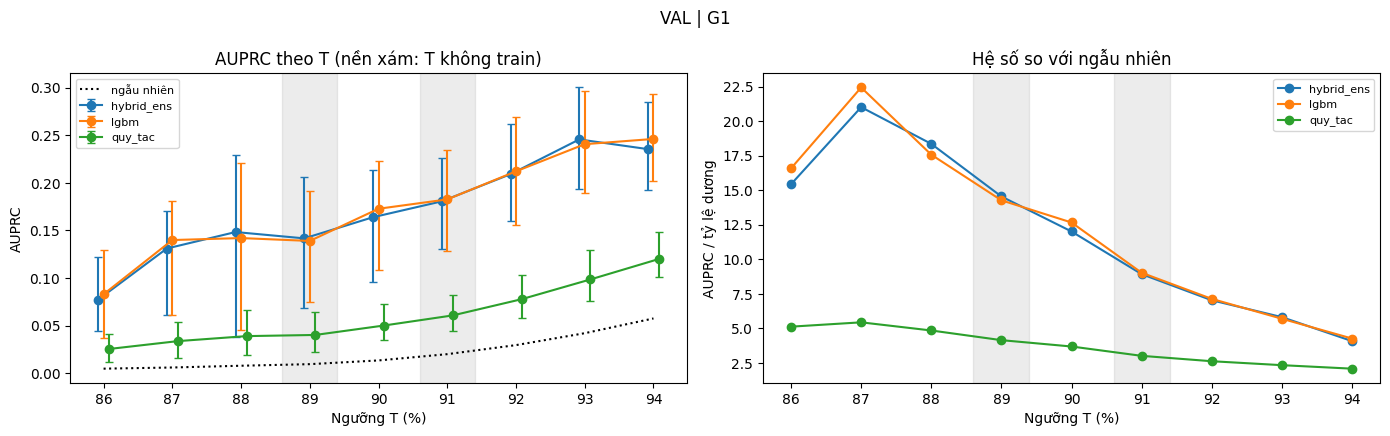

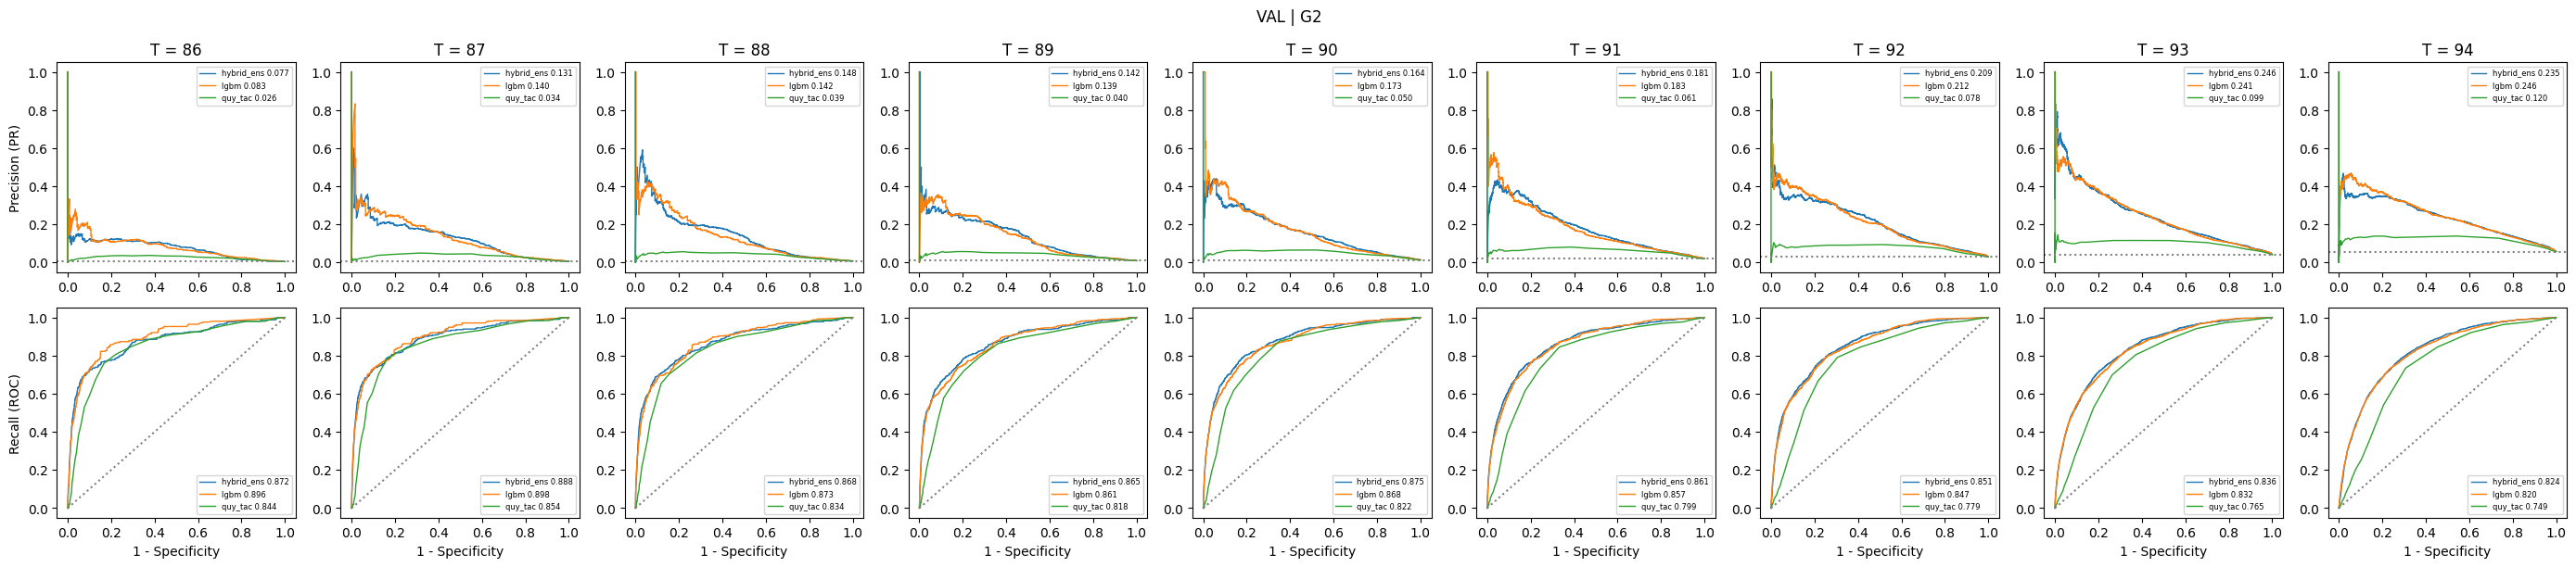

In [8]:
def rule_matrix(k):
    # luật: SpO2 thấp nhất 10 phút cuối càng thấp so với T thì rủi ro càng cao
    mn10 = np.nan_to_num(ST[k]["lv"]["mn_min10"].to_numpy(np.float32), nan=100.0)
    return (T_LIST[None, :] - mn10[:, None]).astype(np.float32)

def all_scores(k):
    S = {f"hybrid_s{s}": sig(seed_scores("main", s, k, NM)) for s in CFG["SEEDS"]}
    S["hybrid_ens"] = np.mean([S[f"hybrid_s{s}"] for s in CFG["SEEDS"]], 0)
    for n, p in CFG["BASELINES"].items():
        if os.path.exists(f"{p}_{k}.npz"):
            z = np.load(f"{p}_{k}.npz"); assert (z["T_list"] == T_LIST).all() and len(z["S"]) == len(DS[k]["X"]); S[n] = z["S"]
        else: print(f"Chưa có {p}_{k}.npz → chạy 10_lightgbm_tc.ipynb trước để có đối chứng '{n}'")
    S["quy_tac"] = rule_matrix(k); return S

dv = DS["val"]; S_val = all_scores("val")
MODELS = [n for n in ("hybrid_ens", "lgbm", "quy_tac") if n in S_val]; SEEDN = [f"hybrid_s{s}" for s in CFG["SEEDS"]]
R_val = pd.concat([E.by_T(n, S_val[n], dv, T_LIST, holdout=T_HO) for n in MODELS + SEEDN], ignore_index=True)
print("AUPRC trên val theo T:"); display(R_val.pivot(index="T", columns="model", values="AUPRC").round(4))
print("Trung bình AUPRC ở T train / T không train:")
display(R_val.groupby(["model", "holdout"])["AUPRC"].mean().unstack().round(4).rename(columns={False: "T train", True: "T không train"}))
E.plot_auprc_by_T(R_val[R_val.model.isin(MODELS)], T_HO, "VAL | G1")
E.plot_pr_roc_by_T({n: S_val[n] for n in MODELS}, dv, T_LIST, "VAL | G2")

### 5.2 Tính đơn điệu (G4), hiệu chuẩn (G5) và bảng ngưỡng theo cửa sổ
- **G4:** với mọi cửa sổ val, tính P ở mọi T rồi đếm tỷ lệ cặp vi phạm (T cao hơn mà P thấp hơn). LightGBM có ràng buộc đơn điệu nên phải bằng 0; hybrid chỉ được phạt mềm nên kỳ vọng gần 0.
- **G5:** đường hiệu chuẩn theo T. Xác suất do ta lấy mẫu con phía âm và có trọng số bù nên gần đúng về thang, nhưng chỉ cần cho hiển thị; quyết định cảnh báo dùng ngưỡng chọn theo báo giả.
- Bảng ngưỡng **đếm theo cửa sổ** (0,04 / 0,2 / 0,5 / 1 báo giả mỗi giờ) chỉ để tham khảo; ngưỡng thật chọn ở mục 7 bằng mô phỏng.

Vi phạm đơn điệu trên val (adjacent: cặp T kề nhau; windows_any: cửa sổ có ít nhất một vi phạm):


,adjacent,all_pairs,windows_any,max_drop
hybrid_s1,0.00074,0.00022,0.00517,0.02024
hybrid_s2,0.00052,0.00018,0.00337,0.03625
hybrid_s3,0.00405,0.00176,0.01794,0.00925
hybrid_ens,0.00010,0.00003,0.00071,0.00634
lgbm,0.00000,0.00000,0.00000,0.00000


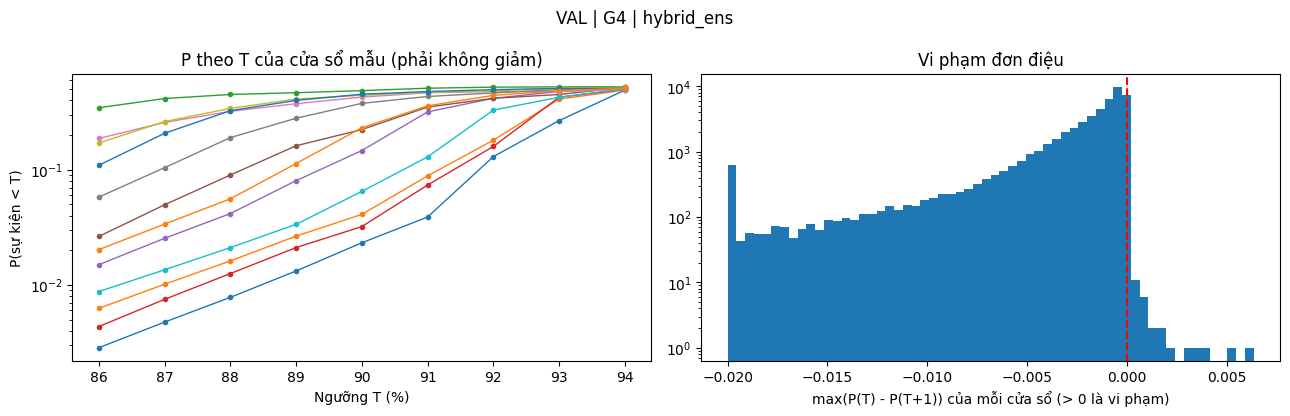

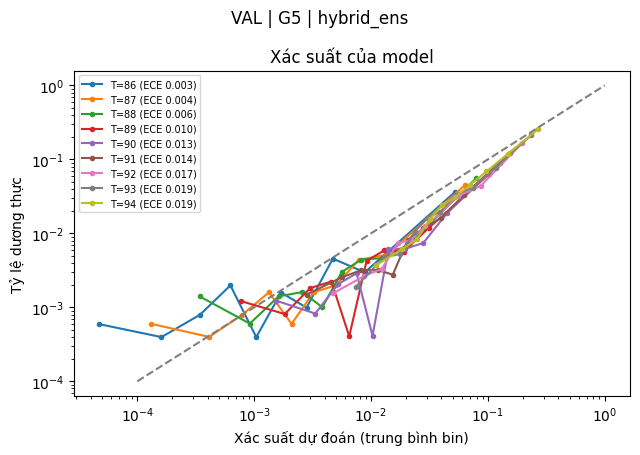

Ngưỡng xác suất theo T, chọn theo báo giả/giờ ĐẾM THEO CỬA SỔ (cận trên, chỉ tham khảo):


,0.04,0.20,0.50,1.00
T,,,,
86,0.2135,0.0744,0.0316,0.0153
87,0.2224,0.0884,0.0434,0.0230
88,0.2266,0.1074,0.0593,0.0330
89,0.2638,0.1423,0.0812,0.0472
90,0.2881,0.1711,0.1063,0.0648
91,0.2868,0.1978,0.1341,0.0866
92,0.3403,0.2435,0.1709,0.1165
93,0.3498,0.2802,0.2097,0.1503
94,0.3836,0.3118,0.2458,0.1848


In [9]:
MONO_V = pd.DataFrame({n: E.monotonic_report(S_val[n], T_LIST) for n in S_val if n != "quy_tac"}).T
print("Vi phạm đơn điệu trên val (adjacent: cặp T kề nhau; windows_any: cửa sổ có ít nhất một vi phạm):"); display(MONO_V.round(5))
E.plot_monotonic(S_val["hybrid_ens"], T_LIST, dv["pid"], title="VAL | G4 | hybrid_ens")
E.plot_reliability_by_T(S_val["hybrid_ens"], dv, T_LIST, title="VAL | G5 | hybrid_ens")
print("Ngưỡng xác suất theo T, chọn theo báo giả/giờ ĐẾM THEO CỬA SỔ (cận trên, chỉ tham khảo):")
display(E.thr_table(S_val["hybrid_ens"], dv, T_LIST, fa_levels=(0.04, 0.2, 0.5, 1)).round(4))

## 6. Ablation (G8)
Mỗi biến thể train **một seed** (`ABL_SEED`), so với model chính cùng seed:

| Biến thể | Khác model chính ở | Câu hỏi trả lời |
|---|---|---|
| `no_base` | bỏ 3 đặc trưng baseline | baseline của từng bệnh nhân có giúp không? |
| `abs` | đầu vào tuyệt đối (không trừ T; `frac_below` ở 90/92/95 cố định), T vẫn là đầu vào | biểu diễn tương đối có tốt hơn không? |
| `per_T` | 7 model riêng, mỗi model một T (như bản v2) | model chung có thua model riêng không? |

Model riêng không có ở T = 89, 91, nên đó chính là điểm yếu của cách cũ: muốn T mới thì phải train lại. Đặt `RUN_ABLATION=False` để bỏ qua (tốn thời gian nhất notebook).

♻ no_base/s1: tiếp tục từ epoch 40 (tốt nhất epoch 39, val_auprc 0.1612)
✔ no_base/s1: đã xong (val_auprc 0.1612 ở epoch 39)
♻ abs/s1: tiếp tục từ epoch 28 (tốt nhất epoch 22, val_auprc 0.1564)
✔ abs/s1: đã xong (val_auprc 0.1564 ở epoch 22)
♻ perT_86/s1: tiếp tục từ epoch 36 (tốt nhất epoch 30, val_auprc 0.0922)
✔ perT_86/s1: đã xong (val_auprc 0.0922 ở epoch 30)
♻ perT_87/s1: tiếp tục từ epoch 25 (tốt nhất epoch 19, val_auprc 0.1161)
✔ perT_87/s1: đã xong (val_auprc 0.1161 ở epoch 19)
♻ perT_88/s1: tiếp tục từ epoch 15 (tốt nhất epoch 14, val_auprc 0.1210)


perT_88/s1:  38%|###7      | 15/40 [00:00<?, ?epoch/s]

 Ep |    loss   mono val_loss |  auprc val_auprc ho_auprc |   viol |  giây | ghi chú


Epoch 16:   0%|          | 0/140 [00:00<?, ?it/s]

 16 |  0.0360 0.0000   0.0368 |  0.185    0.1153      nan |    nan |     9 | 


...

Epoch 16:   0%|          | 0/120 [00:00<?, ?it/s]

 16 |  0.1710 0.0000   0.1822 |  0.240    0.2268      nan |    nan |     7 | 


Epoch 17:   0%|          | 0/120 [00:00<?, ?it/s]

 17 |  0.1702 0.0000   0.1818 |  0.240    0.2289      nan |    nan |     5 | 
■ Dừng: hết kiên nhẫn (early stopping)


model,abs,main,no_base,per_T
T,,,,
86,0.0770,0.0726,0.0698,0.0922
87,0.1107,0.1180,0.1245,0.1161
88,0.1255,0.1344,0.1230,0.1298
89,0.1250,0.1301,0.1173,NaN
90,0.1399,0.1569,0.1587,0.1397
91,0.1577,0.1698,0.1765,NaN
92,0.1921,0.2079,0.1970,0.2107
93,0.2227,0.2396,0.2245,0.2375
94,0.2268,0.2250,0.2310,0.2300


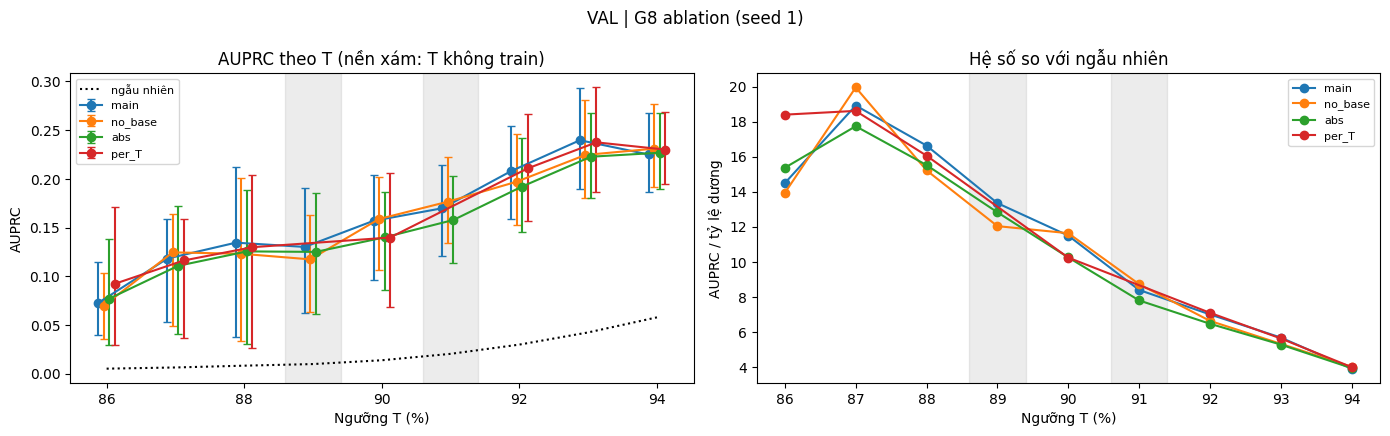

Chênh AUPRC (main − biến thể), CI 95% theo bệnh nhân:


,bien_the,T,chenh_lo,chenh_hi,ket_luan
0,no_base,86,0.0008,0.0129,main tốt hơn
1,no_base,87,-0.0259,0.0065,chưa phân biệt
2,no_base,88,-0.0213,0.0301,chưa phân biệt
3,no_base,90,-0.0299,0.0212,chưa phân biệt
4,no_base,92,-0.0045,0.0273,chưa phân biệt
5,no_base,93,-0.0061,0.0341,chưa phân biệt
6,no_base,94,-0.0174,0.0081,chưa phân biệt
7,abs,86,-0.0299,0.0114,chưa phân biệt
8,abs,87,-0.0540,0.0349,chưa phân biệt
9,abs,88,-0.0295,0.0316,chưa phân biệt


In [10]:
if CFG["RUN_ABLATION"]:
    s0 = CFG["ABL_SEED"]; ABL = {"main": sig(seed_scores("main", s0, "val", NM))}
    for nme, var in {"no_base": dict(rel=True, use_base=False), "abs": dict(rel=False, use_base=True)}.items():
        train_run(nme, s0, var); ABL[nme] = sig(seed_scores(nme, s0, "val", get_norm(var["rel"], var["use_base"])))
    S_pt = np.full_like(ABL["main"], np.nan)
    for T in T_TR:
        train_run(f"perT_{T}", s0, dict(rel=True, use_base=True, fixed_T=T))
        S_pt[:, C.col(dv, T)] = sig(seed_scores(f"perT_{T}", s0, "val", NM, [T]))[:, C.col(dv, T)]
    ABL["per_T"] = S_pt
    R_abl = pd.concat([E.by_T(n, S, dv, T_LIST, holdout=T_HO) for n, S in ABL.items()], ignore_index=True)
    display(R_abl.pivot(index="T", columns="model", values="AUPRC").round(4))
    E.plot_auprc_by_T(R_abl, T_HO, f"VAL | G8 ablation (seed {s0})")
    rows = []
    for n in ABL:
        if n == "main": continue
        for T in T_TR:
            j = C.col(dv, T); ok = dv["OK"][:, j]; lo, hi = E.paired_diff(ABL["main"][ok, j], ABL[n][ok, j], dv["Y"][ok, j], dv["pid"][ok])
            rows.append(dict(bien_the=n, T=T, chenh_lo=lo, chenh_hi=hi, ket_luan="main tốt hơn" if lo > 0 else "main kém hơn" if hi < 0 else "chưa phân biệt"))
    print("Chênh AUPRC (main − biến thể), CI 95% theo bệnh nhân:"); display(pd.DataFrame(rows).round(4))

## 7. Mô phỏng cảnh báo trên val

### 7.1 Timeline và chọn persistence
Mỗi T có một timeline riêng: sự kiện định nghĩa tại T (đã loại sự kiện nhiễu bằng HR, giống nhãn), điểm rủi ro là các cửa sổ `OK` tại T. `sweep_fa_day` so các cấu hình `k/n` và cooldown **ở cùng mức báo giả/ngày thật** (ngưỡng tự chọn để đạt ngân sách). Chọn cấu hình bắt được nhiều sự kiện nhất ở ngân sách mong muốn rồi ghi vào `CFG["TIERS"]`.

Lưu ý: timeline không có các cửa sổ ngay sau một sự kiện (đầu vào đã chứa sự kiện, phần đó do tầng Critical đảm nhiệm), nên báo giả/ngày có thể hơi lạc quan.

,T,fa_budget,k,n,cooldown,alerts_per_day,FA_per_day,FA_day_pt_p90,precision,caught_useful,missed,lead_med
0,88,0.5,1,1,30,0.637,0.498,0.869,0.218,0.219,0.677,10.0
1,88,1.0,1,1,30,1.222,0.990,2.174,0.190,0.302,0.510,10.0
2,88,2.0,1,1,30,2.287,1.992,5.449,0.129,0.438,0.396,11.0
3,88,3.0,1,1,30,3.294,2.976,7.763,0.097,0.469,0.344,11.0
4,88,0.5,1,1,60,0.596,0.498,1.079,0.165,0.156,0.750,9.5
5,88,1.0,1,1,60,1.175,0.973,2.495,0.172,0.312,0.583,12.5
6,88,2.0,1,1,60,2.177,1.969,5.579,0.096,0.333,0.573,11.0
7,88,3.0,1,1,60,3.184,2.964,8.835,0.069,0.365,0.542,11.0
8,88,0.5,2,3,30,0.614,0.498,0.869,0.189,0.219,0.750,17.5
9,88,1.0,2,3,30,1.175,0.973,2.287,0.172,0.333,0.594,16.0


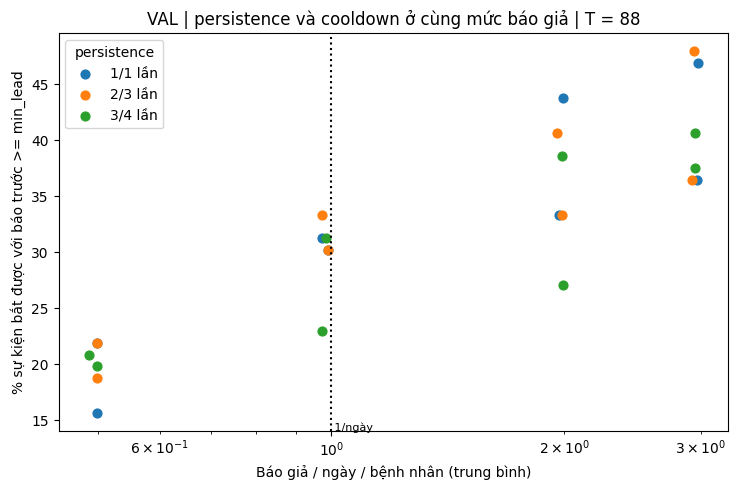

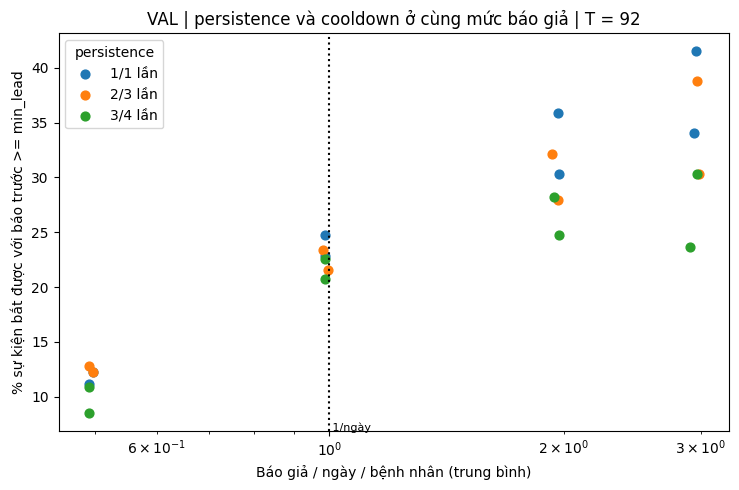

In [11]:
CACHE = {"val": SA.load_records(dv["rec"], CFG["CLEAN_DIR"])}
def timelines(S, k, T_list=T_LIST):
    d = DS[k]
    return {int(T): SA.build_timelines(S[:, C.col(d, T)], d, T=int(T), cache=CACHE[k], clean_events=True,
                                       mask=d["OK"][:, C.col(d, T)]) for T in T_list}
TLv = {n: timelines(S_val[n], "val") for n in MODELS}
SW = pd.concat([SA.sweep_fa_day(TLv["hybrid_ens"][T], fa_days=(0.5, 1, 2, 3)).assign(T=T) for T in (88, 92) if T in TLv["hybrid_ens"]])
display(SW[["T"] + SA.SHOW].round(3))
for T, g in SW.groupby("T"): SA.plot_tradeoff(g, title=f"VAL | persistence và cooldown ở cùng mức báo giả | T = {T}")

### 7.2 Bảng T → ngưỡng (chọn trên val)
Với từng T **train** và từng tầng, chọn ngưỡng nhỏ nhất mà báo giả/ngày thật trên val không vượt ngân sách (`fa_day`). Sau đó làm mượt trên thang logit theo T (`THR_SMOOTH`) và nội suy cho mọi T nguyên trong `T_RANGE`. Ngưỡng ở T = 89, 91 vì thế đến từ **nội suy**, đúng như khi bác sĩ đặt một T mới. Mỗi đối chứng (LightGBM, luật) có bảng riêng ở cùng ngân sách, để so sánh công bằng.

thô (val)         làm mượt        
       watch   alert    watch   alert
T                                    
86    0.0349  0.0685   0.0349  0.0685
87    0.0489  0.0901   0.0489  0.0901
88    0.0668  0.1196   0.0668  0.1196
90    0.1223  0.1949   0.1223  0.1949
92    0.1957  0.2659   0.1957  0.2659
93    0.2337  0.3052   0.2337  0.3052
94    0.2694  0.3288   0.2694  0.3288
85       NaN     NaN   0.0349  0.0685
89       NaN     NaN   0.0908  0.1535
91       NaN     NaN   0.1555  0.2285
95       NaN     NaN   0.2694  0.3288

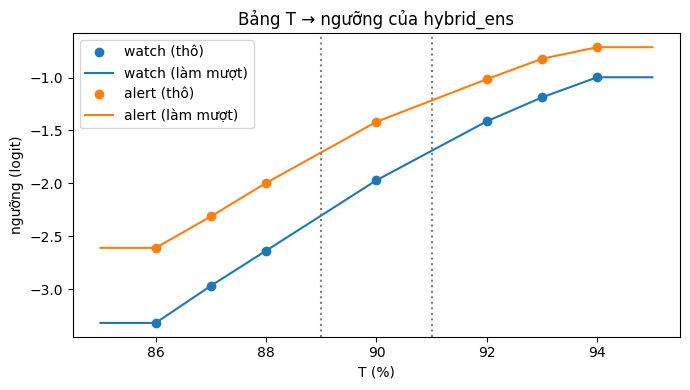

VAL | hybrid_ens với bảng ngưỡng đã làm mượt (kiểm tra ngân sách; T không train dùng ngưỡng nội suy):


,T,tier,holdout,alerts_per_day,FA_per_day,FA_day_pt_p90,precision,caught_useful,lead_med,evaluable
0,86,watch,False,3.097,2.909,7.094,0.061,0.525,15.5,59
1,86,alert,False,1.084,0.981,1.485,0.095,0.322,12.0,59
2,87,watch,False,3.248,2.961,8.289,0.088,0.519,11.0,77
3,87,alert,False,1.182,0.987,2.182,0.165,0.377,10.5,77
4,88,watch,False,3.294,2.976,7.763,0.097,0.469,11.0,96
5,88,alert,False,1.175,0.973,2.495,0.172,0.312,12.5,96
6,89,watch,True,3.367,3.022,7.924,0.102,0.458,16.0,131
7,89,alert,True,1.245,0.999,2.754,0.197,0.344,13.0,131
8,90,watch,False,3.472,2.992,8.670,0.138,0.508,13.0,177
9,90,alert,False,1.330,0.985,3.140,0.259,0.379,13.0,177


In [12]:
T_OUT = range(CFG["T_RANGE"][0], CFG["T_RANGE"][1] + 1)
def stream_thr_table(TL, T_list=T_TR):
    return pd.DataFrame({t: {int(T): SA.thr_for_fa_day(TL[int(T)], c["fa_day"], c["k"], c["n"], c["cooldown"]) for T in T_list}
                         for t, c in CFG["TIERS"].items()}).rename_axis("T")
THR_RAW = {n: stream_thr_table(TLv[n]) for n in MODELS}
THR = {n: (E.smooth_table(THR_RAW[n], T_OUT, CFG["THR_SMOOTH"]) if n != "quy_tac" else
           THR_RAW[n].reindex(list(T_OUT)).interpolate(limit_direction="both")) for n in MODELS}    # luật: điểm không phải xác suất
display(pd.concat({"thô (val)": THR_RAW["hybrid_ens"], "làm mượt": THR["hybrid_ens"]}, axis=1).round(4))
fig, ax = plt.subplots(figsize=(7, 4))
for i, t in enumerate(CFG["TIERS"]):
    ax.plot(THR_RAW["hybrid_ens"].index, E.logit(THR_RAW["hybrid_ens"][t]), "o", c=f"C{i}", label=f"{t} (thô)")
    ax.plot(THR["hybrid_ens"].index, E.logit(THR["hybrid_ens"][t]), "-", c=f"C{i}", label=f"{t} (làm mượt)")
for t in T_HO: ax.axvline(t, c="gray", ls=":")
ax.set(xlabel="T (%)", ylabel="ngưỡng (logit)", title="Bảng T → ngưỡng của hybrid_ens"); ax.legend(); plt.tight_layout(); plt.show()

def tier_table(TL, thr_tab, T_list=T_LIST):
    rows, leads, pts = [], {}, {}
    for T in T_list:
        for t, c in CFG["TIERS"].items():
            s, pt, l = SA.run_stream(TL[int(T)], float(thr_tab.loc[int(T), t]), c["k"], c["n"], c["cooldown"])
            rows.append(dict(T=int(T), tier=t, holdout=int(T) in T_HO, **s))
            if t == "alert": leads[int(T)], pts[int(T)] = l, pt
    return pd.DataFrame(rows), leads, pts
G6_COLS = ["T", "tier", "holdout", "alerts_per_day", "FA_per_day", "FA_day_pt_p90", "precision", "caught_useful", "lead_med", "evaluable"]
TV, LV, _ = tier_table(TLv["hybrid_ens"], THR["hybrid_ens"])
print("VAL | hybrid_ens với bảng ngưỡng đã làm mượt (kiểm tra ngân sách; T không train dùng ngưỡng nội suy):"); display(TV[G6_COLS].round(3))

### 7.3 G3 trên val: AI hơn luật ở điểm nào?
Với mỗi model, mỗi T và mỗi ngân sách trong `FA_GRID`: chọn ngưỡng trên val (cấu hình tầng Alert) rồi đo tỷ lệ sự kiện bắt được với báo trước ≥ 5 phút. Đường của model nằm **trên** đường của luật nghĩa là ở **cùng số báo giả/ngày**, model bắt được nhiều sự kiện hơn.

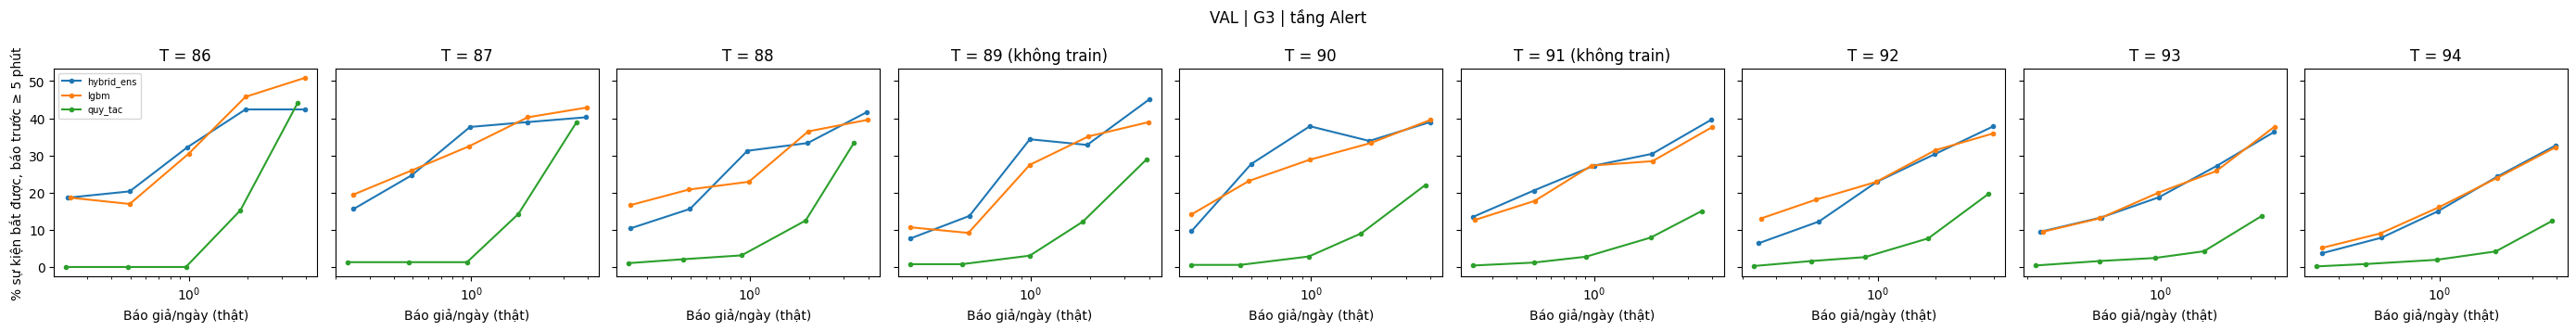

model         hybrid_ens   lgbm  quy_tac
T  fa_budget                            
86 0.25            0.186  0.186    0.000
   0.50            0.203  0.169    0.000
   1.00            0.322  0.305    0.000
   2.00            0.424  0.458    0.153
   4.00            0.424  0.508    0.441
87 0.25            0.156  0.195    0.013
   0.50            0.247  0.260    0.013
   1.00            0.377  0.325    0.013
   2.00            0.390  0.403    0.143
   4.00            0.403  0.429    0.390
88 0.25            0.104  0.167    0.010
   0.50            0.156  0.208    0.021
   1.00            0.312  0.229    0.031
   2.00            0.333  0.365    0.125
   4.00            0.417  0.396    0.333
89 0.25            0.076  0.107    0.008
   0.50            0.137  0.092    0.008
   1.00            0.344  0.275    0.031
   2.00            0.328  0.351    0.122
   4.00            0.450  0.389    0.290
90 0.25            0.096  0.141    0.006
   0.50            0.277  0.232    0.006
   1.00            0.379  0.288    0.028
   2.00            0.339  0.333    0.090
   4.00            0.390  0.395    0.220
91 0.25            0.134  0.126    0.004
   0.50            0.206  0.178    0.012
   1.00            0.273  0.273    0.028
   2.00            0.304  0.285    0.079
   4.00            0.395  0.375    0.150
92 0.25            0.064  0.130    0.003
   0.50            0.122  0.181    0.016
   1.00            0.229  0.229    0.027
   2.00            0.303  0.314    0.077
   4.00            0.378  0.359    0.197
93 0.25            0.095  0.095    0.004
   0.50            0.133  0.131    0.016
   1.00            0.188  0.200    0.024
   2.00            0.272  0.258    0.042
   4.00            0.363  0.377    0.137
94 0.25            0.037  0.052    0.002
   0.50            0.079  0.090    0.008
   1.00            0.150  0.161    0.019
   2.00            0.243  0.240    0.042
   4.00            0.327  0.322    0.124

In [13]:
CA = CFG["TIERS"]["alert"]
G3_THR = {(n, T, fa): SA.thr_for_fa_day(TLv[n][T], fa, CA["k"], CA["n"], CA["cooldown"])
          for n in MODELS for T in TLv[n] for fa in CFG["FA_GRID"]}
def g3_table(TL):
    return pd.DataFrame([dict(model=n, T=T, fa_budget=fa, **SA.run_stream(TL[n][T], th, CA["k"], CA["n"], CA["cooldown"])[0])
                         for (n, T, fa), th in G3_THR.items()])
def plot_g3(df, title):
    Ts = sorted(df["T"].unique()); fig, ax = plt.subplots(1, len(Ts), figsize=(3.1 * len(Ts), 3.6), sharey=True, squeeze=False)
    for a, T in zip(ax[0], Ts):
        for n, g in df[df["T"] == T].groupby("model", sort=False): a.plot(g["FA_per_day"], g["caught_useful"] * 100, "o-", ms=3, label=n)
        a.set(xscale="log", xlabel="Báo giả/ngày (thật)", title=f"T = {T}" + (" (không train)" if T in T_HO else ""))
    ax[0][0].set_ylabel("% sự kiện bắt được, báo trước ≥ 5 phút"); ax[0][0].legend(fontsize=7)
    fig.suptitle(title); plt.tight_layout(); plt.show()
G3V = g3_table(TLv); plot_g3(G3V, "VAL | G3 | tầng Alert")
display(G3V.pivot_table(index=["T", "fa_budget"], columns="model", values="caught_useful").round(3))

## 8. Chốt cấu hình
Trước khi mở test, ghi lại mọi lựa chọn đã làm trên val: seed triển khai, cấu hình tầng, phương pháp làm mượt bảng ngưỡng. Từ đây **không đổi gì** sau khi đã xem test.

In [14]:
DEPLOY = max(CFG["SEEDS"], key=lambda s: RUNS[s]["best"])
FROZEN = dict(deploy_seed=int(DEPLOY), tiers=CFG["TIERS"], thr_smooth=CFG["THR_SMOOTH"], lambda_mono=CFG["LAMBDA_MONO"],
              thr_table_hybrid_ens=THR["hybrid_ens"].round(6).to_dict(), time=time.strftime("%Y-%m-%d %H:%M"))
json.dump(FROZEN, open(f"{ROOT}/frozen_config.json", "w", encoding="utf-8"), indent=1, default=str)
print(json.dumps({k: v for k, v in FROZEN.items() if k != "thr_table_hybrid_ens"}, indent=1, default=str))

{
 "deploy_seed": 3,
 "tiers": {
  "watch": {
   "fa_day": 3.0,
   "k": 1,
   "n": 1,
   "cooldown": 30
  },
  "alert": {
   "fa_day": 1.0,
   "k": 1,
   "n": 1,
   "cooldown": 60
  }
 },
 "thr_smooth": "isotonic",
 "lambda_mono": 1.0,
 "time": "2026-10-16 18:44"
}


## 9. Đánh giá cuối trên test (chạy một lần)
Chỉ chạy sau mục 8. Ngưỡng, persistence, cooldown, seed đều giữ nguyên từ val.

### 9.1 Phân biệt: G1, G2 và so sánh cặp theo T
Chênh AUPRC (hybrid_ens − đối chứng) lấy mẫu lại theo bệnh nhân: khoảng không chứa 0 thì khác biệt có ý nghĩa.

AUPRC trên test theo T:


model,hybrid_ens,hybrid_s1,hybrid_s2,hybrid_s3,lgbm,quy_tac
T,,,,,,
86,0.0485,0.0404,0.0519,0.0479,0.0523,0.0152
87,0.0596,0.0548,0.0581,0.0606,0.0679,0.0243
88,0.0989,0.0916,0.0959,0.1027,0.1047,0.0366
89,0.1407,0.1284,0.1388,0.1444,0.1431,0.0486
90,0.1762,0.1583,0.1679,0.1897,0.1820,0.0565
91,0.1798,0.1612,0.1731,0.1799,0.1783,0.0656
92,0.1788,0.1717,0.1749,0.1795,0.2024,0.0825
93,0.2133,0.1994,0.2100,0.2137,0.2238,0.1026
94,0.2347,0.2220,0.2319,0.2321,0.2405,0.1136


,model,T,holdout,AUPRC,lo,hi,lift,AUROC,prevalence,n_pos,pat_pos
0,hybrid_ens,86,False,0.0485,0.0130,0.1441,13.4979,0.8109,0.0036,192,17
1,hybrid_ens,87,False,0.0596,0.0432,0.0929,10.8513,0.8503,0.0055,292,21
2,hybrid_ens,88,False,0.0989,0.0626,0.1339,11.9312,0.8636,0.0083,437,25
3,hybrid_ens,89,True,0.1407,0.0945,0.2032,11.4941,0.8671,0.0122,637,30
4,hybrid_ens,90,False,0.1762,0.0928,0.2618,10.3909,0.8482,0.0170,862,37
5,hybrid_ens,91,True,0.1798,0.1158,0.2540,7.6752,0.8309,0.0234,1151,46
6,hybrid_ens,92,False,0.1788,0.1352,0.2221,5.4324,0.8192,0.0329,1546,57
7,hybrid_ens,93,False,0.2133,0.1766,0.2502,4.7429,0.8223,0.0450,1966,63
8,hybrid_ens,94,False,0.2347,0.1990,0.2740,4.0931,0.8057,0.0573,2247,69
9,lgbm,86,False,0.0523,0.0114,0.1335,14.5518,0.8044,0.0036,192,17


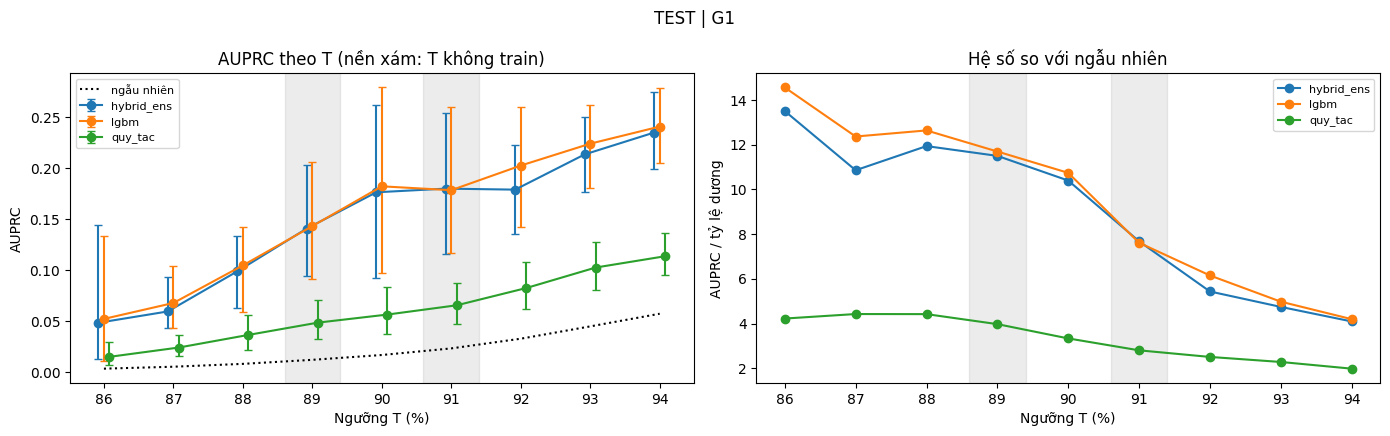

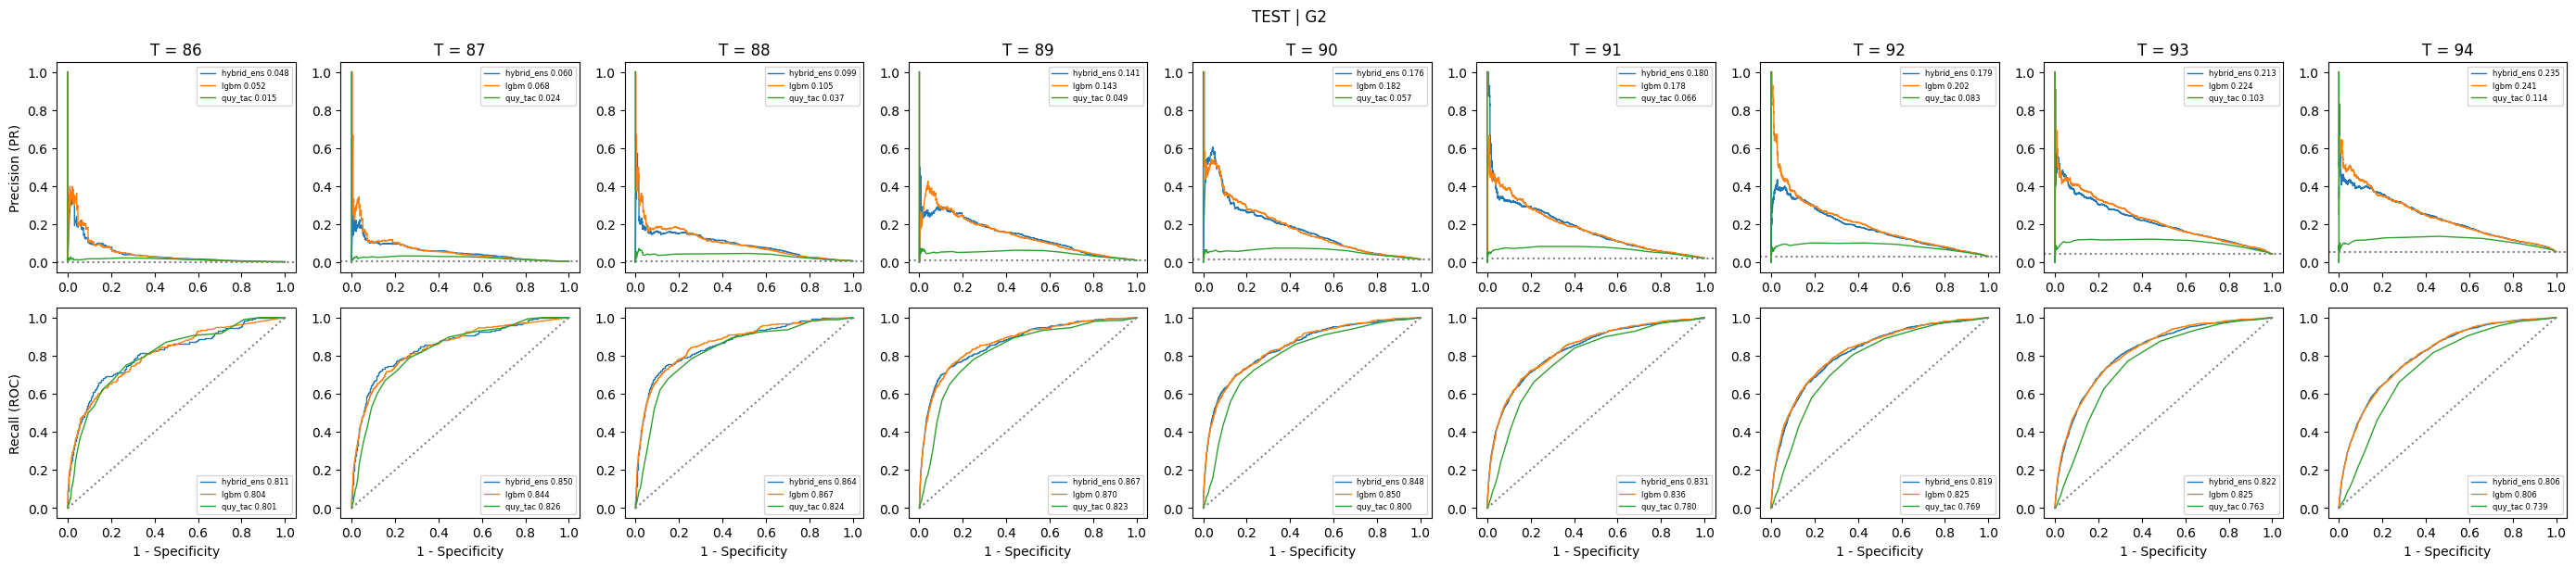

Chênh AUPRC (hybrid_ens − đối chứng), CI 95% theo bệnh nhân:


,doi_chung,T,lo,hi,ket_luan
0,lgbm,86,-0.0294,0.0152,chưa phân biệt
1,lgbm,87,-0.0345,0.0088,chưa phân biệt
2,lgbm,88,-0.0200,0.0129,chưa phân biệt
3,lgbm,89,-0.0215,0.0159,chưa phân biệt
4,lgbm,90,-0.0222,0.0208,chưa phân biệt
5,lgbm,91,-0.0155,0.0144,chưa phân biệt
6,lgbm,92,-0.0462,-0.0040,hybrid kém hơn
7,lgbm,93,-0.0335,0.0076,chưa phân biệt
8,lgbm,94,-0.0264,0.0107,chưa phân biệt
9,quy_tac,86,0.0033,0.1145,hybrid tốt hơn


In [15]:
# CHẠY MỘT LẦN
dt = DS["test"]; S_test = all_scores("test")
R_test = pd.concat([E.by_T(n, S_test[n], dt, T_LIST, holdout=T_HO) for n in MODELS + SEEDN], ignore_index=True)
print("AUPRC trên test theo T:"); display(R_test.pivot(index="T", columns="model", values="AUPRC").round(4))
display(R_test[R_test.model.isin(MODELS)][["model", "T", "holdout", "AUPRC", "lo", "hi", "lift", "AUROC", "prevalence", "n_pos", "pat_pos"]].round(4))
E.plot_auprc_by_T(R_test[R_test.model.isin(MODELS)], T_HO, "TEST | G1")
E.plot_pr_roc_by_T({n: S_test[n] for n in MODELS}, dt, T_LIST, "TEST | G2")
PD = []
for n in MODELS[1:]:
    for T in T_LIST:
        j = C.col(dt, T); ok = dt["OK"][:, j]; lo, hi = E.paired_diff(S_test["hybrid_ens"][ok, j], S_test[n][ok, j], dt["Y"][ok, j], dt["pid"][ok])
        PD.append(dict(doi_chung=n, T=int(T), lo=lo, hi=hi, ket_luan="hybrid tốt hơn" if lo > 0 else "hybrid kém hơn" if hi < 0 else "chưa phân biệt"))
PD = pd.DataFrame(PD); print("Chênh AUPRC (hybrid_ens − đối chứng), CI 95% theo bệnh nhân:"); display(PD.round(4))

### 9.2 Đơn điệu (G4) và hiệu chuẩn (G5)
Isotonic theo T được fit trên **val** và áp lên test (bảng phải). Isotonic chỉ để hiển thị trên dashboard.

,adjacent,all_pairs,windows_any,max_drop
hybrid_s1,0.00099,0.00028,0.00691,0.02049
hybrid_s2,0.00073,0.00025,0.00459,0.03632
hybrid_s3,0.00343,0.00127,0.01901,0.00868
hybrid_ens,0.00012,0.00004,0.00079,0.00622
lgbm,0.00000,0.00000,0.00000,0.00000


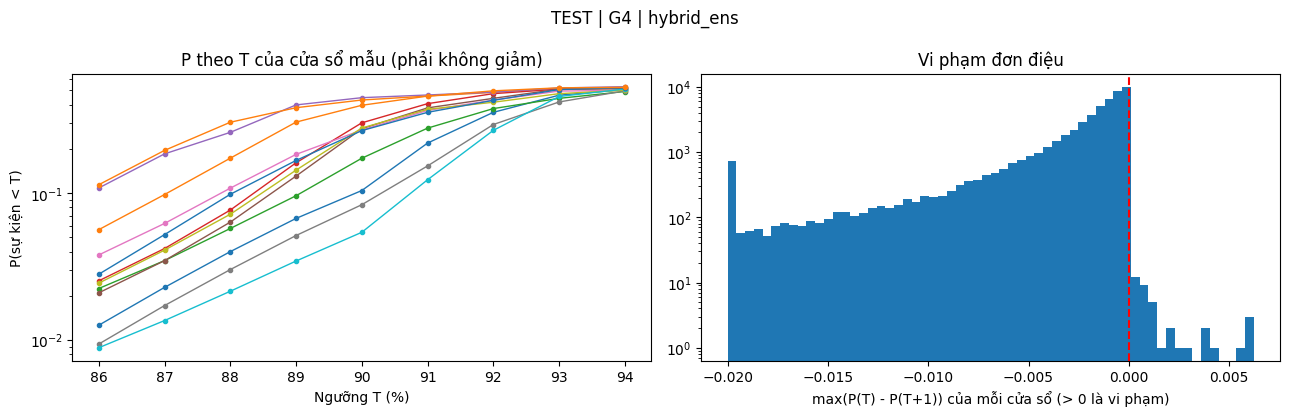

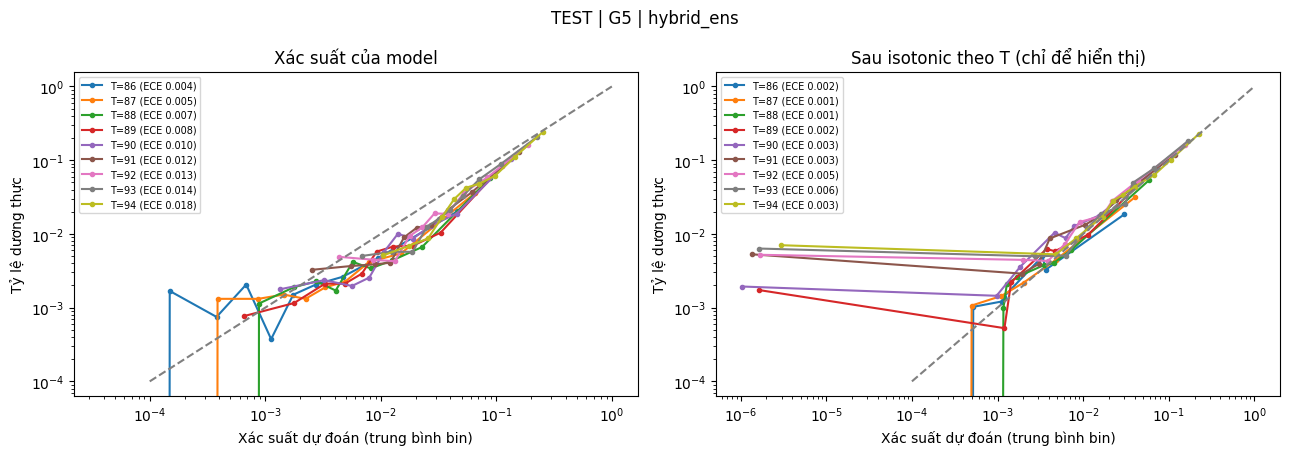

In [16]:
display(pd.DataFrame({n: E.monotonic_report(S_test[n], T_LIST) for n in S_test if n != "quy_tac"}).T.round(5))
E.plot_monotonic(S_test["hybrid_ens"], T_LIST, dt["pid"], title="TEST | G4 | hybrid_ens")
CAL = E.fit_calibrators(S_val["hybrid_ens"], dv, T_LIST)
E.plot_reliability_by_T(S_test["hybrid_ens"], dt, T_LIST, cal=CAL, title="TEST | G5 | hybrid_ens")

### 9.3 Vận hành: G6, G7, G3 trên test
- **G6:** mỗi T, mỗi tầng: cảnh báo/ngày, báo giả/ngày (trung bình và phân vị 90 theo bệnh nhân), precision, tỷ lệ bắt được với báo trước ≥ 5 phút, báo trước trung vị. Mỗi model dùng bảng ngưỡng **của chính nó** chọn trên val ở cùng ngân sách.
- **G7:** histogram thời gian báo trước theo T và phân phối báo giả theo bệnh nhân (tầng Alert).
- **G3:** như mục 7.3, ngưỡng từ val, đo trên test.

TEST | G6:


,model,T,tier,holdout,alerts_per_day,FA_per_day,FA_day_pt_p90,precision,caught_useful,lead_med,evaluable
0,hybrid_ens,86,watch,False,3.261,3.158,7.470,0.031,0.429,11.5,42
1,hybrid_ens,86,alert,False,1.100,1.035,2.416,0.059,0.238,9.0,42
2,hybrid_ens,87,watch,False,3.532,3.342,9.361,0.054,0.529,15.0,68
3,hybrid_ens,87,alert,False,1.213,1.127,2.897,0.071,0.250,14.0,68
4,hybrid_ens,88,watch,False,3.718,3.402,9.626,0.085,0.531,15.0,98
5,hybrid_ens,88,alert,False,1.327,1.174,3.405,0.115,0.235,13.0,98
6,hybrid_ens,89,watch,True,3.842,3.399,10.266,0.115,0.503,14.0,147
7,hybrid_ens,89,alert,True,1.412,1.179,3.690,0.165,0.259,13.0,147
8,hybrid_ens,90,watch,False,3.620,3.014,8.876,0.167,0.541,15.0,231
9,hybrid_ens,90,alert,False,1.394,1.025,3.682,0.264,0.307,14.0,231


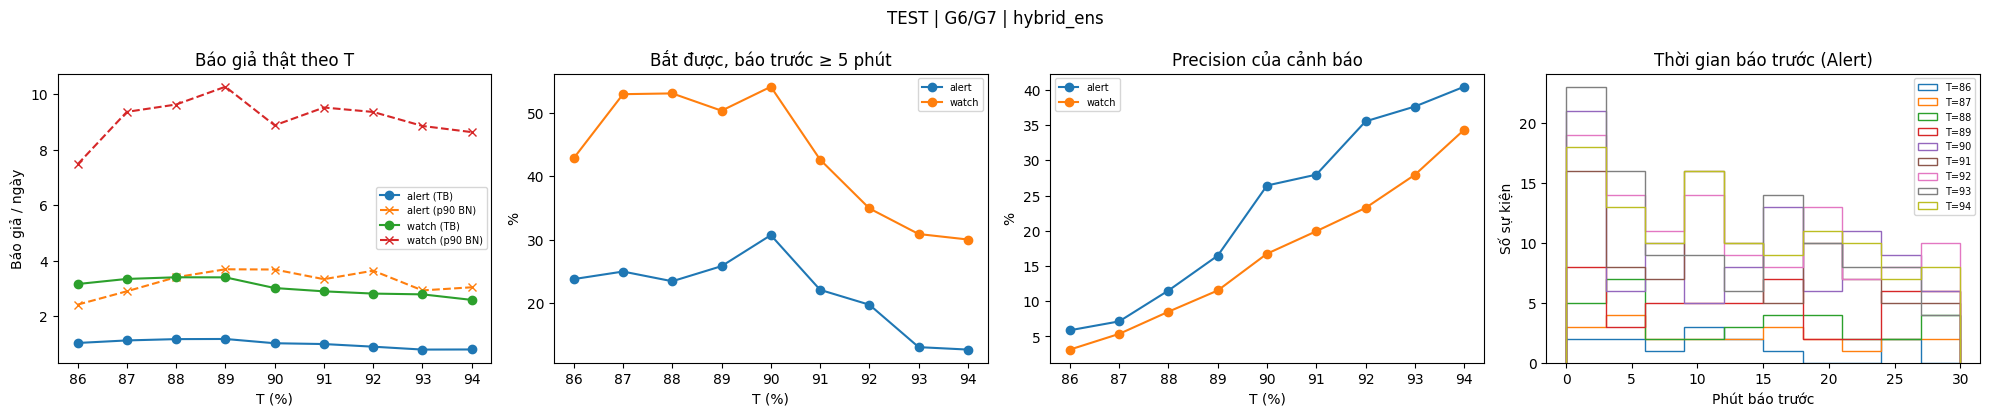

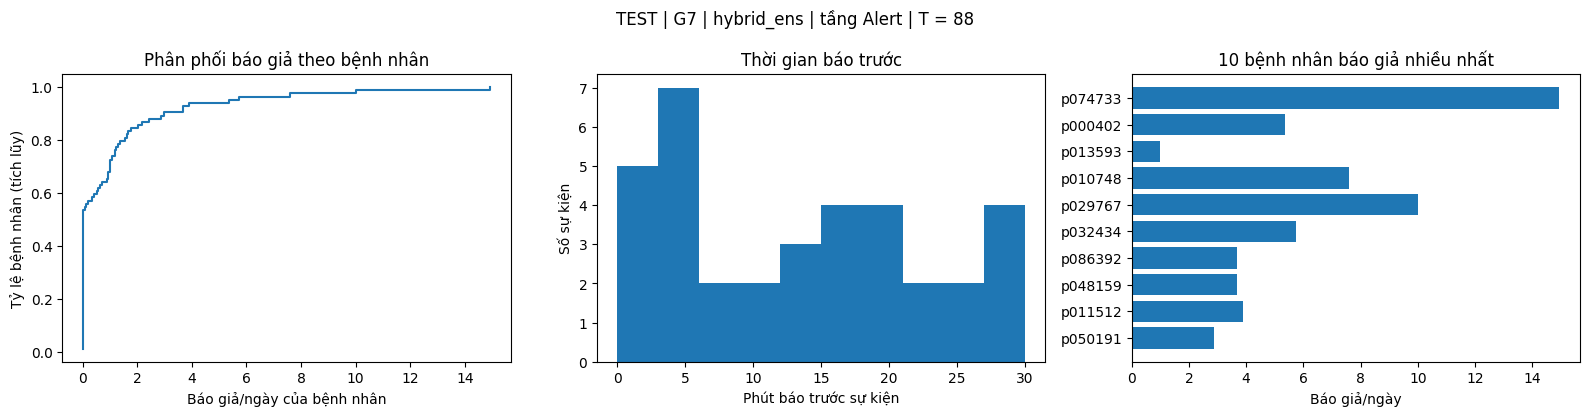

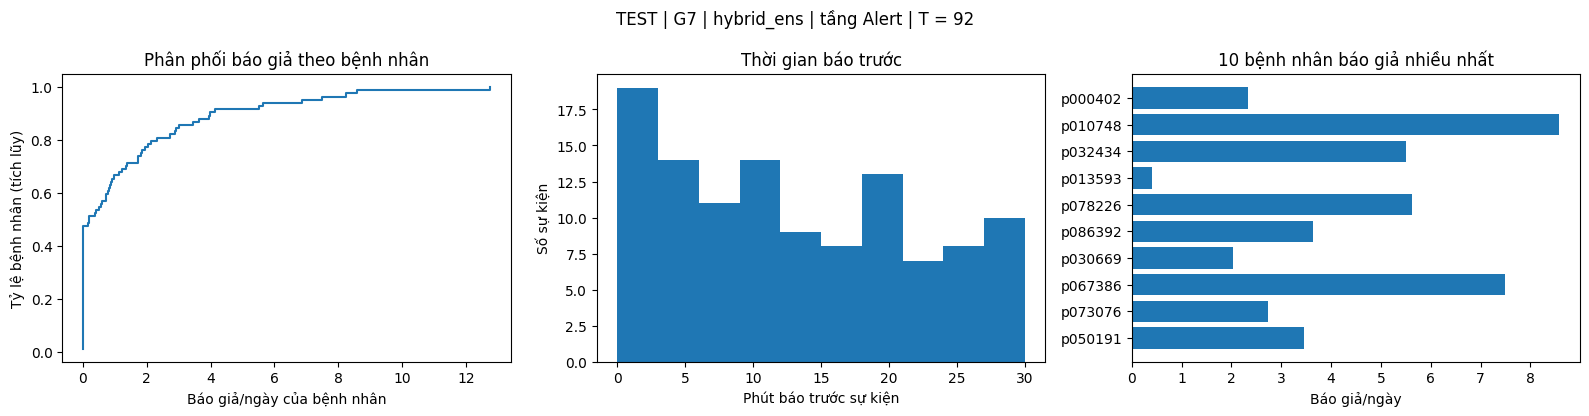

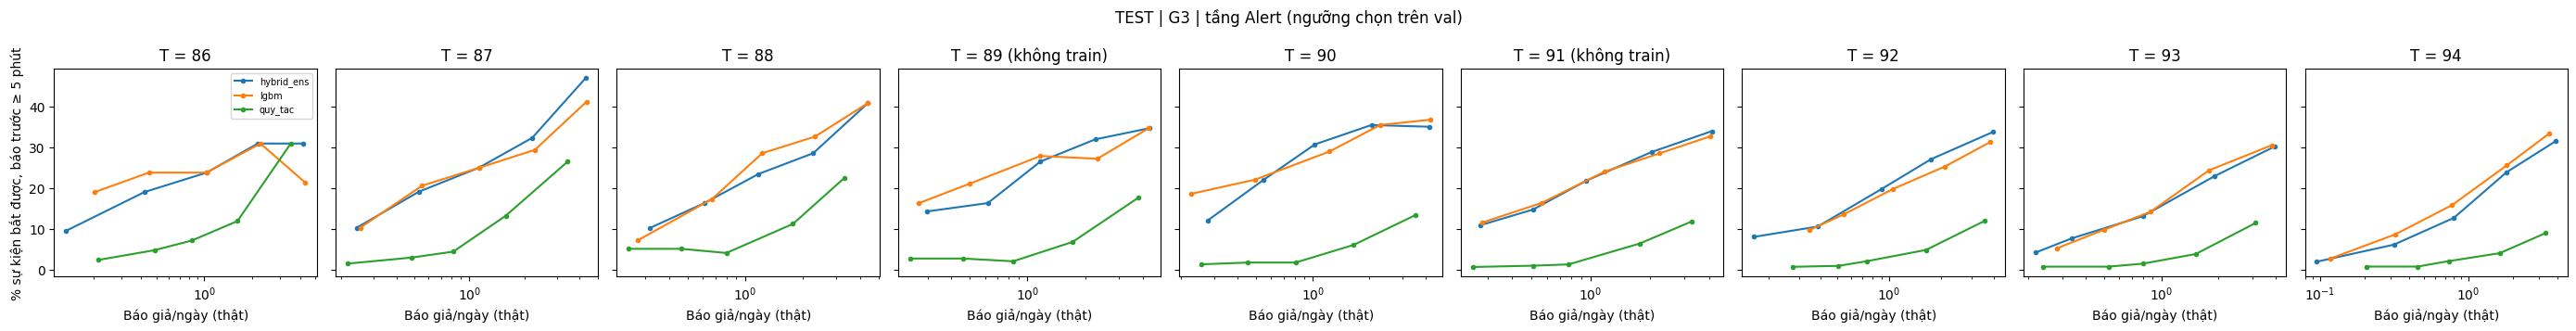

FA_per_day                caught_useful               
model        hybrid_ens   lgbm quy_tac    hybrid_ens   lgbm quy_tac
T  fa_budget                                                       
86 0.25           0.135  0.205   0.216         0.095  0.190   0.024
   0.50           0.420  0.447   0.485         0.190  0.238   0.048
   1.00           1.035  1.029   0.835         0.238  0.238   0.071
   2.00           2.172  2.258   1.617         0.310  0.310   0.119
   4.00           4.215  4.306   3.503         0.310  0.214   0.310
87 0.25           0.244  0.255   0.217         0.103  0.103   0.015
   0.50           0.531  0.552   0.482         0.191  0.206   0.029
   1.00           1.127  1.132   0.818         0.250  0.250   0.044
   2.00           2.205  2.280   1.582         0.324  0.294   0.132
   4.00           4.317  4.344   3.429         0.471  0.412   0.265
88 0.25           0.317  0.273   0.246         0.102  0.071   0.051
   0.50           0.612  0.672   0.464         0.163  0.173   0.051
   1.00           1.174  1.229   0.797         0.235  0.286   0.041
   2.00           2.272  2.321   1.780         0.286  0.327   0.112
   4.00           4.379  4.374   3.298         0.408  0.408   0.224
89 0.25           0.299  0.271   0.244         0.143  0.163   0.027
   0.50           0.620  0.498   0.459         0.163  0.211   0.027
   1.00           1.168  1.168   0.841         0.265  0.279   0.020
   2.00           2.259  2.314   1.722         0.320  0.272   0.068
   4.00           4.313  4.296   3.803         0.347  0.347   0.177
90 0.25           0.278  0.227   0.255         0.121  0.186   0.013
   0.50           0.550  0.493   0.453         0.221  0.221   0.017
   1.00           1.025  1.229   0.810         0.307  0.290   0.017
   2.00           2.051  2.278   1.649         0.355  0.355   0.061
   4.00           4.187  4.215   3.524         0.351  0.368   0.134
91 0.25           0.275  0.281   0.252         0.109  0.115   0.006
   0.50           0.510  0.563   0.510         0.147  0.163   0.010
   1.00           0.950  1.178   0.774         0.218  0.240   0.013
   2.00           2.040  2.239   1.782         0.288  0.285   0.064
   4.00           4.132  4.056   3.282         0.340  0.327   0.119
92 0.25           0.166  0.343   0.276         0.080  0.097   0.007
   0.50           0.386  0.546   0.509         0.106  0.136   0.009
   1.00           0.901  1.048   0.742         0.198  0.198   0.021
   2.00           1.747  2.091   1.631         0.271  0.253   0.048
   4.00           3.979  3.820   3.556         0.338  0.313   0.120
93 0.25           0.217  0.283   0.237         0.042  0.053   0.007
   0.50           0.336  0.501   0.527         0.076  0.098   0.007
   1.00           0.797  0.876   0.797         0.131  0.142   0.015
   2.00           1.897  1.779   1.515         0.229  0.244   0.038
   4.00           3.933  3.814   3.136         0.302  0.305   0.115
94 0.25           0.096  0.118   0.206         0.019  0.027   0.007
   0.50           0.316  0.323   0.456         0.061  0.087   0.007
   1.00           0.801  0.779   0.742         0.127  0.158   0.021
   2.00           1.815  1.815   1.631         0.239  0.256   0.040
   4.00           3.887  3.535   3.321         0.315  0.335   0.090

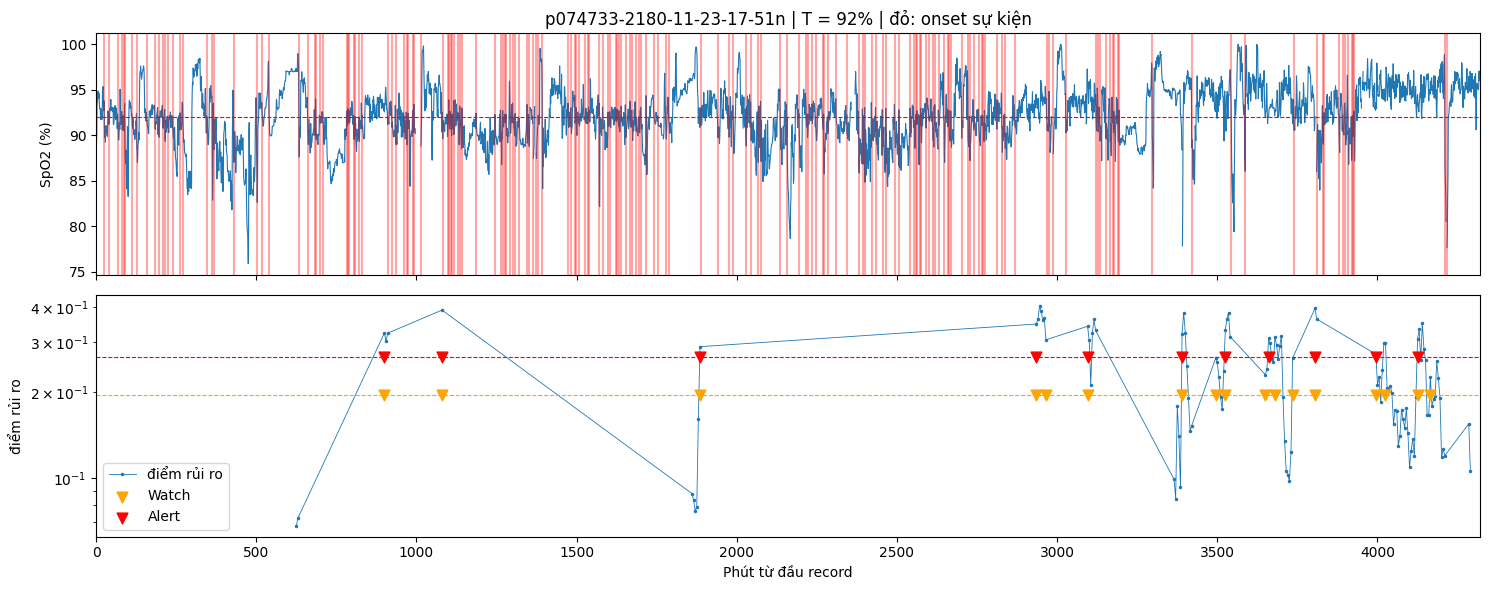

In [17]:
CACHE["test"] = SA.load_records(dt["rec"], CFG["CLEAN_DIR"])
TLt = {n: timelines(S_test[n], "test") for n in MODELS}
G6, LEADS, PTS = {}, {}, {}
for n in MODELS: G6[n], LEADS[n], PTS[n] = tier_table(TLt[n], THR[n])
G6T = pd.concat({n: g[G6_COLS] for n, g in G6.items()}, names=["model", None]).reset_index(level=0)
print("TEST | G6:"); display(G6T.round(3))
SA.plot_by_T(G6["hybrid_ens"], LEADS["hybrid_ens"], "TEST | G6/G7 | hybrid_ens")
for T in (88, 92):
    if T in PTS["hybrid_ens"]: SA.plot_config(PTS["hybrid_ens"][T], LEADS["hybrid_ens"][T], f"TEST | G7 | hybrid_ens | tầng Alert | T = {T}")
G3T = g3_table(TLt); plot_g3(G3T, "TEST | G3 | tầng Alert (ngưỡng chọn trên val)")
display(G3T.pivot_table(index=["T", "fa_budget"], columns="model", values=["FA_per_day", "caught_useful"]).round(3))
w_, a_ = CFG["TIERS"]["watch"], CFG["TIERS"]["alert"]; Tx = 92 if 92 in TLt["hybrid_ens"] else int(T_LIST[-1])
t0_ = TLt["hybrid_ens"][Tx]; rec0 = max(t0_, key=lambda r: len(t0_[r]["onsets"]) if len(t0_[r]["t"]) > 50 else -1)
SA.plot_example(t0_, THR["hybrid_ens"].loc[Tx, "watch"], THR["hybrid_ens"].loc[Tx, "alert"],
                (w_["k"], w_["n"], w_["cooldown"]), (a_["k"], a_["n"], a_["cooldown"]), rec=rec0)

### 9.4 Tầng Critical (G10)
Critical là **luật**, không dùng ML: SpO₂ < ngưỡng Critical liên tục `n_min` phút với SQI (`spo2_valid`) tốt, hoặc mạch ngoài `[hr_low, hr_high]` liên tục `n_min` phút. Bảng cho thấy gánh nặng cảnh báo của luật theo từng ngưỡng Critical, có và không có luật nhịp tim. Thống kê trên toàn bộ phút có dữ liệu của các record test.

TEST | G10 | tầng Critical (luật):


,crit_T,luat_HR,alerts_per_day,spo2_per_day,hr_per_day,FA_day_pt_med,FA_day_pt_p90,FA_day_pt_max,pct_patients_any,n_events,patients
0,80,False,0.089,0.089,0.000,0.000,0.246,1.558,0.158,18,76
1,80,True,0.468,0.079,0.389,0.000,1.278,5.921,0.329,95,76
2,82,False,0.123,0.123,0.000,0.000,0.462,2.493,0.211,25,76
3,82,True,0.492,0.108,0.384,0.000,1.331,6.232,0.342,100,76
4,85,False,0.241,0.241,0.000,0.000,0.766,4.053,0.289,49,76
5,85,True,0.601,0.222,0.379,0.000,1.383,6.544,0.408,122,76
6,88,False,0.714,0.714,0.000,0.000,1.826,8.090,0.434,145,76
7,88,True,1.019,0.684,0.335,0.071,2.803,8.427,0.500,207,76


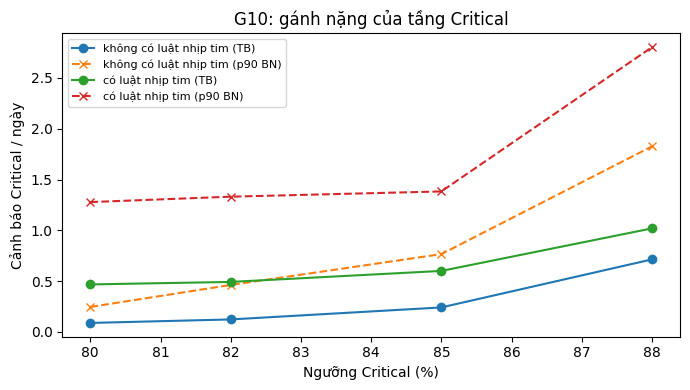

In [18]:
tl_all = {r: dict(pid=pid_, spo2=c["spo2_mean"], valid=c["spo2_valid"], pulse=c["pulse_mean"], onsets=np.array([], int),
                  valid_h=np.isfinite(c["spo2_mean"]).sum() / 60)
          for r, c in CACHE["test"].items() for pid_ in [dt["pid"][dt["rec"] == r][0]]}
cr = CFG["CRIT"]; G10 = []
for ct in cr["crit_T"]:
    for use_hr in (False, True):
        s = SA.critical_stats(tl_all, cr["cooldown"], crit_T=ct, n_min=cr["n_min"], sqi_min=cr["sqi_min"],
                              hr_low=cr["hr_low"] if use_hr else None, hr_high=cr["hr_high"] if use_hr else None)
        G10.append(dict(crit_T=ct, luat_HR=use_hr, **s))
G10 = pd.DataFrame(G10); print("TEST | G10 | tầng Critical (luật):"); display(G10.round(3))
fig, ax = plt.subplots(figsize=(7, 4))
for use_hr, g in G10.groupby("luat_HR"):
    ax.plot(g["crit_T"], g["alerts_per_day"], "o-", label=("có" if use_hr else "không có") + " luật nhịp tim (TB)")
    ax.plot(g["crit_T"], g["FA_day_pt_p90"], "x--", label=("có" if use_hr else "không có") + " luật nhịp tim (p90 BN)")
ax.set(xlabel="Ngưỡng Critical (%)", ylabel="Cảnh báo Critical / ngày", title="G10: gánh nặng của tầng Critical"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 10. Xuất model cho ESP32-C3 (models_v3)

| File | Nội dung |
|---|---|
| `hybrid_tc.keras` | model Keras (seed triển khai) |
| `hybrid_tc_int8.tflite` | INT8, hai đầu vào (`seq`, `tab`), đầu ra logit |
| `hybrid_tc_norm.npz` | `seq_mu`, `seq_sd` (thang tương đối), `tab_cols`, `tab_med`, `tab_mu`, `tab_sd`, `fb_grid`, `base_min_hours` |
| `hybrid_tc_meta.json` | thứ tự đầu vào, thang lượng tử hóa, **bảng T → ngưỡng** (xác suất, logit, int8) cho Watch/Alert, khoảng T hợp lệ, persistence, cooldown, cấu hình Critical và baseline, `model_version` |

**Quyết định kỹ thuật**
- Dữ liệu đại diện cho lượng tử hóa: 1.200 mẫu ngẫu nhiên + 300 mẫu dương, mỗi mẫu một T ngẫu nhiên, truyền dạng **dict theo tên đầu vào** (converter sắp xếp đầu vào theo tên; firmware đưa dữ liệu đúng `input_order`).
- **Bảng ngưỡng cho thiết bị chọn lại trên điểm INT8 của val** (đúng thứ thiết bị tính), cùng quy trình mục 7.2.
- Firmware: chuỗi `(x − [T, T, 0, 0] − seq_mu)/seq_sd`, NaN → 0, thêm 2 mask; bảng đặc trưng tính như `tc_core.make_features`, điền `tab_med`, z-score, cắt ±5; lượng tử hóa theo `scale`, `zero_point`. Server gửi bảng ngưỡng trong config `dev/{id}/config` có version; web chặn T ngoài `T_valid_range`.
- G9: so logit float và INT8 trên val (scatter) và chênh AUPRC theo T.

In [19]:
EXP, NAME = CFG["EXPORT_DIR"], CFG["NAME"]; os.makedirs(EXP, exist_ok=True)
best = load_best("main", DEPLOY); best.save(f"{EXP}/{NAME}.keras")
np.savez(f"{EXP}/{NAME}_norm.npz", **{k: np.asarray(v) for k, v in NM.items()}, fb_grid=C.FB_GRID, base_min_hours=C.BASE_MIN_HOURS)

rng = np.random.default_rng(0); dtr = DS["train"]
ri, rT, ry, _ = C.sample_epoch(dtr, T_TR, 1.0, rng)
rep_i, rep_T = np.r_[ri[:1200], ri[ry == 1][:300]], np.r_[rT[:1200], rT[ry == 1][:300]]
REP = C.inputs(dtr, ST["train"], NM, rep_T, rep_i)
conv = tf.lite.TFLiteConverter.from_keras_model(best)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = lambda: ({"seq": REP["seq"][i:i + 1], "tab": REP["tab"][i:i + 1]} for i in range(len(rep_i)))
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = conv.inference_output_type = tf.int8
TFL = f"{EXP}/{NAME}_int8.tflite"; open(TFL, "wb").write(conv.convert())

def interp(batch):
    it = tf.lite.Interpreter(model_path=TFL)
    for x in it.get_input_details(): it.resize_tensor_input(x["index"], [batch] + list(x["shape"][1:]))
    it.allocate_tensors(); return it
IT1 = interp(1); det = IT1.get_input_details(); d_seq = next(x for x in det if len(x["shape"]) == 3); d_tab = next(x for x in det if len(x["shape"]) == 2)
osc, ozp = IT1.get_output_details()[0]["quantization"]
q = lambda x, dd: np.clip(np.round(x / dd["quantization"][0] + dd["quantization"][1]), -128, 127).astype(np.int8)
def tflite_logit(X, it=IT1, B=1):
    di = {len(x["shape"]): x["index"] for x in it.get_input_details()}; oi = it.get_output_details()[0]["index"]
    n = len(X["seq"]); out = np.empty(n, np.float32)
    for a in range(0, n, B):
        s_, t_ = X["seq"][a:a + B], X["tab"][a:a + B]; m = len(s_)
        if m < B: s_, t_ = np.concatenate([s_, np.repeat(s_[-1:], B - m, 0)]), np.concatenate([t_, np.repeat(t_[-1:], B - m, 0)])
        it.set_tensor(di[3], q(s_, d_seq)); it.set_tensor(di[2], q(t_, d_tab)); it.invoke()
        out[a:a + m] = (it.get_tensor(oi)[:m, 0].astype(np.float32) - ozp) * osc
    return out
try:                                                     # chạy theo lô cho nhanh; kiểm tra khớp với lô 1
    ITB = interp(256); chk = {k: v[:300] for k, v in REP.items()}
    assert np.allclose(tflite_logit(chk, ITB, 256), tflite_logit(chk)); run_q = lambda X: tflite_logit(X, ITB, 256)
except Exception as e:
    print("Không chạy theo lô được, dùng lô 1:", e); run_q = tflite_logit

def int8_matrix(k):
    Z = np.full((len(DS[k]["X"]), len(T_LIST)), np.nan, np.float32)
    for T in tqdm(T_LIST, desc=f"INT8 {k}", leave=False): Z[:, C.col(DS[k], T)] = run_q(C.inputs(DS[k], ST[k], NM, int(T)))
    return Z
Zq_val = int8_matrix("val"); Zf_val = seed_scores("main", DEPLOY, "val", NM)
kb = os.path.getsize(TFL) / 1024
print(f"Seed triển khai: {DEPLOY} | TFLite INT8: {kb:.1f} KB (mục tiêu < 30 KB) | tham số: {best.count_params():,} | bước logit đầu ra: {osc:.4f}")

INFO:tensorflow:Assets written to: C:\Users\LENOVO\AppData\Local\Temp\tmppy0r2cxr\assets


INFO:tensorflow:Assets written to: C:\Users\LENOVO\AppData\Local\Temp\tmppy0r2cxr\assets


Saved artifact at 'C:\Users\LENOVO\AppData\Local\Temp\tmppy0r2cxr'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 60, 6), dtype=tf.float32, name='seq'), TensorSpec(shape=(None, 23), dtype=tf.float32, name='tab')]
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2136167599088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2136167604016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2136167608944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2136167646832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2136167654752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2136167646656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2136167656336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2136167657040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2136167659856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2136167712016: Tensor

d:\VEDC2026\SPO2-RESEARCH\respiratory-risk-classifier\.venv\lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
d:\VEDC2026\SPO2-RESEARCH\respiratory-risk-classifier\.venv\lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


INT8 val:   0%|          | 0/9 [00:00<?, ?it/s]

Seed triển khai: 3 | TFLite INT8: 19.7 KB (mục tiêu < 30 KB) | tham số: 8,017 | bước logit đầu ra: 0.0434


model,float,int8,chenh_tuong_doi
T,,,
86,0.0823,0.0812,-0.0137
87,0.1381,0.1341,-0.0291
88,0.1567,0.1521,-0.0292
89,0.1370,0.1328,-0.0306
90,0.1552,0.1536,-0.0103
91,0.1855,0.1829,-0.0142
92,0.2025,0.1988,-0.0186
93,0.2403,0.2342,-0.0257
94,0.2415,0.2376,-0.0164


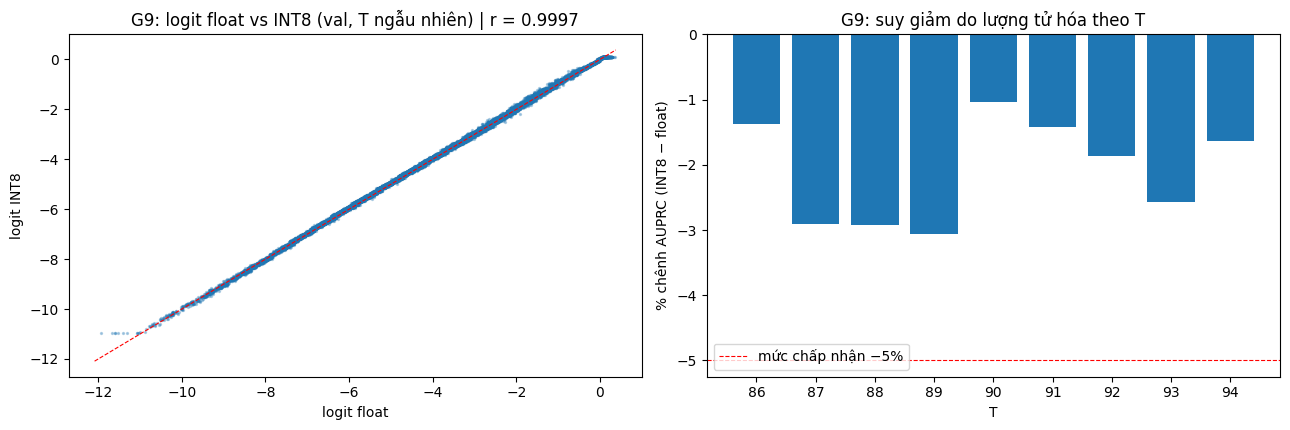

Đã xuất: ['hybrid_tc.keras', 'hybrid_tc_int8.tflite', 'hybrid_tc_meta.json', 'hybrid_tc_norm.npz']


prob          int8      
     watch   alert watch alert
T                             
85  0.0439  0.0912    54    71
86  0.0439  0.0912    54    71
87  0.0636  0.1196    63    79
88  0.0912  0.1555    71    86
89  0.1219  0.2031    79    93
90  0.1613  0.2609    87   101
91  0.2067  0.3003    94   105
92  0.2609  0.3428   101   109
93  0.3048  0.3932   106   114
94  0.3526  0.4141   110   117
95  0.3526  0.4141   110   117

In [20]:
# G9: INT8 so với float trên val
G9 = pd.concat([E.by_T("float", sig(Zf_val), dv, T_LIST, n_boot=0), E.by_T("int8", sig(Zq_val), dv, T_LIST, n_boot=0)])
G9 = G9.pivot(index="T", columns="model", values="AUPRC"); G9["chenh_tuong_doi"] = (G9["int8"] - G9["float"]) / G9["float"]
display(G9.round(4))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4)); rs_ = np.random.default_rng(0)
ii = rs_.choice(len(Zf_val), min(20000, len(Zf_val)), replace=False); jj = rs_.integers(0, len(T_LIST), len(ii))
ax[0].scatter(Zf_val[ii, jj], Zq_val[ii, jj], s=2, alpha=.3); lim = [np.nanmin(Zf_val), np.nanmax(Zf_val)]; ax[0].plot(lim, lim, "r--", lw=.8)
ax[0].set(xlabel="logit float", ylabel="logit INT8", title=f"G9: logit float vs INT8 (val, T ngẫu nhiên) | r = {np.corrcoef(Zf_val[ii, jj], Zq_val[ii, jj])[0, 1]:.4f}")
ax[1].bar(G9.index.astype(str), G9["chenh_tuong_doi"] * 100); ax[1].axhline(-5, c="r", ls="--", lw=.8, label="mức chấp nhận −5%")
ax[1].set(xlabel="T", ylabel="% chênh AUPRC (INT8 − float)", title="G9: suy giảm do lượng tử hóa theo T"); ax[1].legend()
plt.tight_layout(); plt.show()

# bảng ngưỡng cho thiết bị: chọn lại trên điểm INT8 của val (cùng quy trình mục 7.2)
if "val" not in CACHE: CACHE["val"] = SA.load_records(dv["rec"], CFG["CLEAN_DIR"])
THR_DEV = E.smooth_table(stream_thr_table(timelines(sig(Zq_val), "val")), T_OUT, CFG["THR_SMOOTH"])
lg = THR_DEV.apply(E.logit); i8 = np.clip(np.floor(lg / osc + ozp), -128, 127).astype(int)    # cảnh báo khi int8_out > ngưỡng_int8
meta = dict(
    model_version=f"{NAME}-{time.strftime('%Y%m%d')}-s{DEPLOY}", deploy_seed=int(DEPLOY), tflite_kb=round(kb, 1), params=int(best.count_params()),
    input_order=[x["name"] for x in det],
    input_seq=dict(shape=[C.IN_MIN, 6], channels=["spo2_mean-T", "spo2_min-T", "spo2_valid", "pulse_mean", "mask_spo2_mean", "mask_pulse_mean"],
                   scale=float(d_seq["quantization"][0]), zero_point=int(d_seq["quantization"][1])),
    input_tab=dict(shape=[len(NM["tab_cols"])], features=[str(c) for c in NM["tab_cols"]],
                   scale=float(d_tab["quantization"][0]), zero_point=int(d_tab["quantization"][1])),
    output=dict(scale=float(osc), zero_point=int(ozp), kind="logit"),
    T_valid_range=list(CFG["T_RANGE"]), T_train=T_TR, T_holdout=T_HO,
    thresholds=dict(T=[int(t) for t in THR_DEV.index],
                    **{f"{t}_prob": THR_DEV[t].round(6).tolist() for t in THR_DEV}, **{f"{t}_logit": lg[t].round(4).tolist() for t in lg},
                    **{f"{t}_int8": i8[t].tolist() for t in i8}, selected_on="val INT8, báo giả/ngày thật sau persistence+cooldown",
                    smoothing=CFG["THR_SMOOTH"]),
    tiers=CFG["TIERS"], critical=CFG["CRIT_DEPLOY"],
    baseline=dict(definition="trung vị spo2_mean các phút SQI tốt trong 24-72 giờ gần nhất (firmware); train dùng 6-24 giờ trước cửa sổ",
                  min_hours=C.BASE_MIN_HOURS, fallback="SpO2 trung bình của cửa sổ hiện tại, base_hours=0",
                  freeze_during_alert=True, clinician_reference=True),
    unknown_state=dict(rule="spo2_valid trung bình 10 phút cuối < 0.5 hoặc thiếu > 30% phút đầu vào -> UNKNOWN, không chạy model"),
)
json.dump(meta, open(f"{EXP}/{NAME}_meta.json", "w", encoding="utf-8"), indent=1, ensure_ascii=False)
print("Đã xuất:", sorted(f for f in os.listdir(EXP) if f.startswith(NAME))); display(pd.concat({"prob": THR_DEV, "int8": i8}, axis=1).round(4))

## 11. Suy luận thử bằng bản INT8
Mô phỏng đúng việc firmware làm với một cửa sổ test: tính đặc trưng ở mọi T nguyên trong `T_RANGE` (kể cả 85 và 95 chưa từng train), chạy bản `.tflite`, so với bảng ngưỡng trong `meta.json`. Đường P theo T phải không giảm; nếu bác sĩ đổi T từ 88 lên 92 thì cùng một cửa sổ có thể chuyển từ "bình thường" sang WATCH/ALERT mà không cần train lại.

INT8 test:   0%|          | 0/9 [00:00<?, ?it/s]

AUPRC test trung bình (T train) | float seed 3: 0.1466 | INT8: 0.1442


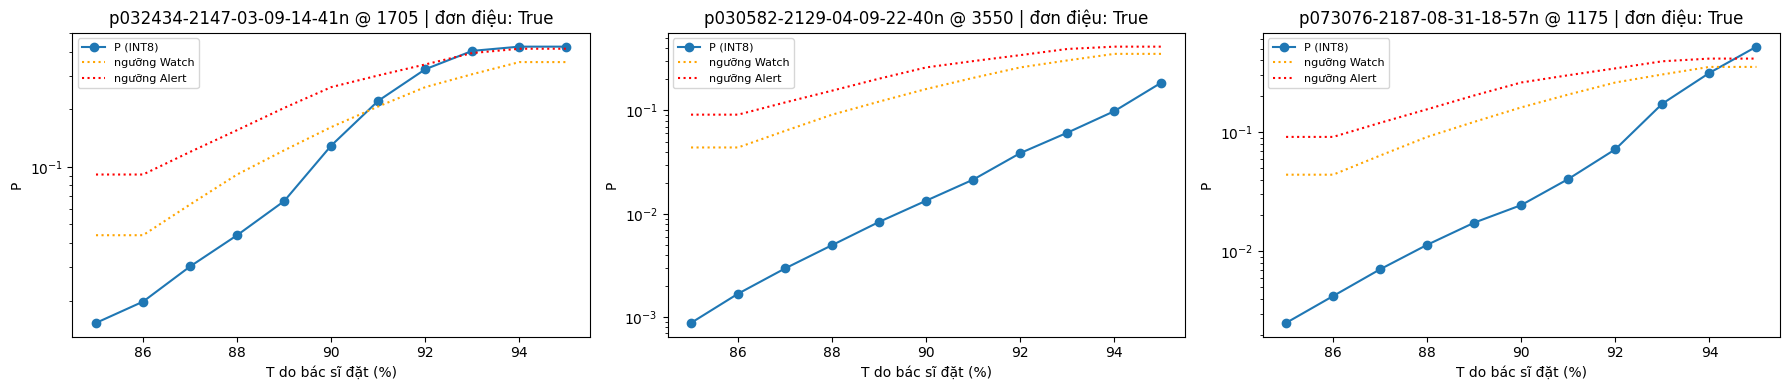

,rec,T=85,T=86,T=87,T=88,T=89,T=90,T=91,T=92,T=93,T=94,T=95
0,p032434-2147-03-09-14-41n,—,—,—,—,—,—,WATCH,WATCH,ALERT,ALERT,ALERT
1,p030582-2129-04-09-22-40n,—,—,—,—,—,—,—,—,—,—,—
2,p073076-2187-08-31-18-57n,—,—,—,—,—,—,—,—,—,—,ALERT


In [21]:
Zq_test = int8_matrix("test"); TT_ = list(T_OUT)
print(f"AUPRC test trung bình (T train) | float seed {DEPLOY}: {E.mean_auprc(seed_scores('main', DEPLOY, 'test', NM), dt, T_TR):.4f} "
      f"| INT8: {E.mean_auprc(Zq_test, dt, T_TR):.4f}")
cand = np.where(dt["Y"][:, C.col(dt, 92)] & dt["OK"][:, C.col(dt, 92)] & ~dt["Y"][:, C.col(dt, 88)].astype(bool))[0]
pick = list(np.random.default_rng(3).choice(cand, min(3, len(cand)), replace=False)) if len(cand) else [0]
fig, ax = plt.subplots(1, len(pick), figsize=(6 * len(pick), 4), squeeze=False); rows = []
for a, i in zip(ax[0], pick):
    P = sig(np.array([run_q(C.inputs(dt, ST["test"], NM, T, [i]))[0] for T in TT_]))
    tier = ["ALERT" if p > THR_DEV.loc[T, "alert"] else "WATCH" if p > THR_DEV.loc[T, "watch"] else "—" for p, T in zip(P, TT_)]
    a.plot(TT_, P, "o-", label="P (INT8)"); a.plot(TT_, THR_DEV["watch"], ":", c="orange", label="ngưỡng Watch"); a.plot(TT_, THR_DEV["alert"], ":", c="r", label="ngưỡng Alert")
    a.set(yscale="log", xlabel="T do bác sĩ đặt (%)", ylabel="P", title=f"{dt['rec'][i]} @ {dt['start'][i]} | đơn điệu: {bool(np.all(np.diff(P) >= -1e-6))}"); a.legend(fontsize=8)
    rows.append({"rec": dt["rec"][i], **{f"T={T}": t for T, t in zip(TT_, tier)}})
plt.tight_layout(); plt.show(); display(pd.DataFrame(rows))

## 12. Tổng kết

### 12.1 Tổng kết tự động

In [22]:
rv = R_test[R_test.model == "hybrid_ens"].set_index("T"); tr_m, ho_m = rv.loc[T_TR, "AUPRC"].mean(), rv.loc[T_HO, "AUPRC"].mean()
nb_ = {t: rv.loc[[t - 1, t + 1], "AUPRC"].mean() for t in T_HO if t - 1 in rv.index and t + 1 in rv.index}
print("TỔNG KẾT (số liệu tự sinh từ các cell phía trên)\n")
print(f"1. Một model cho mọi T: AUPRC test trung bình {tr_m:.3f} ở T train, {ho_m:.3f} ở T không train "
      + "(" + ", ".join(f"T={t}: {rv.loc[t, 'AUPRC']:.3f} so với TB hai T kề {v:.3f}" for t, v in nb_.items()) + ").")
print(f"   Hệ số so với ngẫu nhiên: {rv['lift'].min():.1f}–{rv['lift'].max():.1f} lần.")
for n in MODELS[1:]:
    g = PD[PD.doi_chung == n]; print(f"2. So với {n}: hybrid tốt hơn ở {(g.ket_luan == 'hybrid tốt hơn').sum()}/{len(g)} T, "
                                      f"kém hơn ở {(g.ket_luan == 'hybrid kém hơn').sum()}, chưa phân biệt ở {(g.ket_luan == 'chưa phân biệt').sum()}.")
mv = E.monotonic_report(S_test["hybrid_ens"], T_LIST); print(f"3. Đơn điệu theo T: {mv['adjacent']:.2%} cặp kề nhau vi phạm, {mv['windows_any']:.2%} cửa sổ có vi phạm.")
for T in (88, 92):
    if T in LEADS["hybrid_ens"]:
        h = G6["hybrid_ens"].query("T == @T and tier == 'alert'").iloc[0]
        r_ = G6["quy_tac"].query("T == @T and tier == 'alert'").iloc[0] if "quy_tac" in G6 else None
        print(f"4. Tầng Alert @ T={T}: bắt {h.caught_useful:.0%} sự kiện (báo trước ≥ 5 phút) với {h.FA_per_day:.2f} báo giả/ngày, precision {h.precision:.0%}, "
              f"báo trước trung vị {h.lead_med:.0f} phút" + (f"; luật cùng ngân sách: {r_.caught_useful:.0%} với {r_.FA_per_day:.2f}/ngày." if r_ is not None else "."))
print(f"5. INT8: {meta['tflite_kb']} KB, chênh AUPRC val lớn nhất theo T {G9['chenh_tuong_doi'].min():.1%}" + (" → cần xem lại lượng tử hóa." if G9['chenh_tuong_doi'].min() < -0.05 else " (trong mức 5%)."))

TỔNG KẾT (số liệu tự sinh từ các cell phía trên)

1. Một model cho mọi T: AUPRC test trung bình 0.144 ở T train, 0.160 ở T không train (T=89: 0.141 so với TB hai T kề 0.138, T=91: 0.180 so với TB hai T kề 0.178).
   Hệ số so với ngẫu nhiên: 4.1–13.5 lần.
2. So với lgbm: hybrid tốt hơn ở 0/9 T, kém hơn ở 1, chưa phân biệt ở 8.
2. So với quy_tac: hybrid tốt hơn ở 9/9 T, kém hơn ở 0, chưa phân biệt ở 0.
3. Đơn điệu theo T: 0.01% cặp kề nhau vi phạm, 0.08% cửa sổ có vi phạm.
4. Tầng Alert @ T=88: bắt 23% sự kiện (báo trước ≥ 5 phút) với 1.17 báo giả/ngày, precision 12%, báo trước trung vị 13 phút; luật cùng ngân sách: 4% với 0.80/ngày.
4. Tầng Alert @ T=92: bắt 20% sự kiện (báo trước ≥ 5 phút) với 0.90 báo giả/ngày, precision 36%, báo trước trung vị 11 phút; luật cùng ngân sách: 2% với 0.74/ngày.
5. INT8: 19.7 KB, chênh AUPRC val lớn nhất theo T -3.1% (trong mức 5%).


### 12.2 Lưu ý trung thực khi báo cáo
- **Domain shift:** MIMIC là bệnh nhân ICU đo bằng đầu kẹp ngón tay; vòng đeo đo phản xạ ở cổ tay (MAX30102). MIMIC chỉ dùng để tiền huấn luyện và chứng minh khái niệm.
- **AUPRC tuyệt đối thấp** vì lớp dương hiếm, nhất là ở T thấp; luôn báo cáo kèm hệ số so với ngẫu nhiên và so với luật ở **cùng mức báo giả/ngày**.
- Nếu hybrid vẫn chưa phân biệt được với LightGBM, giá trị cần nhấn mạnh là: một model cho nhiều ngưỡng (kể cả ngưỡng chưa thấy), đơn điệu theo T, đủ nhỏ để chạy trên thiết bị, và hơn luật ở cùng mức báo giả.
- Tầng dự đoán chỉ phủ sự kiện sau một đoạn đầu vào sạch; sự kiện nối tiếp do tầng Critical xử lý. Báo giả/ngày có thể hơi lạc quan do timeline bỏ các cửa sổ ngay sau sự kiện.
- Chưa có mã ICD-9 nên chưa đánh giá theo nhóm bệnh (COPD và không COPD).
- Bộ nhớ (tensor arena) và thời gian suy luận trên ESP32-C3 cần đo trực tiếp trên thiết bị.